# 2.П1. Последовательное тестирование (Sequential Testing)

> **Модуль:** Квази-эксперименты · **Блок:** практический · **Время:** 2.5 ч · **Опирается на:** 2.01, 1.03, 1.06, 1.П2

В лекции 2.01 мы разобрали, почему подглядывание ломает обычный тест и какие методы это чинят. В этой практике ответим на другой вопрос: **как провести A/B-тест, в который смотрят каждый день, чтобы решение осталось честным**. Формулы заново не выводим, а реализуем методы сами, применяем их к логам и проверяем, где они перестают защищать.

**Что сделаем на практике**

1. **Измерим цену подглядывания** на своём расписании взглядов.
2. **Спланируем GST**: посчитаем границы и запас выборки.
3. **Реализуем mSPRT** и выведем, как выбирать параметр $\tau$.
4. **Разберёмся с выручкой**: что на самом деле делает тяжёлый хвост.
5. **Прогоним логи по дням** и получим остановку.
6. **Измерим завышение эффекта** при ранней остановке.
7. **Найдём затухающий эффект** и правило минимальной длительности.
8. **Проверим отклонения от плана**: какие из них ломают гарантию.
9. **Примем решение** и напишем регламент для команды.

Главный вывод практики: статистически честная остановка не означает верное продуктовое решение.

## 0. Подготовка

### Библиотеки

In [1]:
from pathlib import Path
from urllib.parse import quote

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.optimize import brentq

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

BLUE, RED, GREEN, GRAY = "#4C72B0", "#C44E52", "#55A868", "#7F7F7F"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

### Легенда

Сервис бронирования отелей добавил на главную блок **«Горящие предложения»**. Скидочные варианты должны подтолкнуть пользователей к бронированию. В тест приходит около **6 000 новых пользователей в день**, сплит 50/50, поэтому в группе примерно 3 000 человек в день. Единица рандомизации и анализа — пользователь, момент попадания в тест — первый заход на главную.

Продакт хочет смотреть результаты **каждый день** и закончить тест, как только «стало значимо». Обычный z-тест из 1.П2 этого не позволяет, поэтому нам нужен план.

| Метрика | Роль | Что хотим |
|---|---|---|
| Конверсия в бронирование | **основная** | рост, MDE +0.5 п.п. при базе 5% |
| Выручка на пользователя | **основная** | рост |
| Доля пользователей с отменой брони | **контрольная** | не вырасти |

**Правило решения.** Раскатываем блок, если значимо выросла **хотя бы одна** основная метрика и контрольная значимо не ухудшилась.

**Вопрос.** Почему у основных метрик в плане стоит уровень значимости 2.5%, а не 5%?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Шансов на победу два: конверсия и выручка. Если проверять каждую на уровне 5%, вероятность хотя бы одного ложного «раскатываем» при отсутствии эффектов приблизится к 10%. По Бонферрони (лекция 1.03) делим $\alpha$ поровну: 2.5% на метрику. Контрольная метрика в этой поправке не участвует: она не открывает раскатку, а только запрещает её, поэтому лишние проверки по ней не повышают шанс ложного запуска.

</details>

In [2]:
ALPHA = 0.05                 # общий уровень значимости на решение
ALPHA_PRIMARY = ALPHA / 2    # на каждую из двух основных метрик (Бонферрони)
POWER = 0.80
P_BASE = 0.05                # базовая конверсия
MDE = 0.005                  # +0.5 п.п.
N_DAY = 3_000                # пользователей в группе за день
PLAN_DAYS = 14

## 1. Цена подглядывания

### Задание 1. Симуляция на нашем расписании

В лекции подглядывание показано на нормальных приращениях. Проверим его на нашем сценарии: конверсия 5%, по 3 000 пользователей в группе в день, две недели.

Реализуйте `peeking_fpr(look_days, ...)`: для `R` A/A-тестов сгенерируйте дневные числа конверсий из биномиального распределения, посчитайте накопленные итоги и на днях из `look_days` примените z-тест с объединённой долей из 1.П2. Функция возвращает долю тестов, значимых **хотя бы на одном** взгляде.

In [3]:
def peeking_fpr(look_days, p: float = P_BASE, n_day: int = N_DAY, R: int = 100_000,
                alpha: float = ALPHA, seed: int = 1) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [4]:
# @title Решение (нажмите, чтобы раскрыть)
def peeking_fpr(look_days, p: float = P_BASE, n_day: int = N_DAY, R: int = 100_000,
                alpha: float = ALPHA, seed: int = 1) -> float:
    rng = np.random.default_rng(seed)
    look_days = np.asarray(look_days)
    days = look_days.max()
    x_a = rng.binomial(n_day, p, (R, days)).cumsum(axis=1)[:, look_days - 1]
    x_b = rng.binomial(n_day, p, (R, days)).cumsum(axis=1)[:, look_days - 1]
    n = n_day * look_days
    pool = (x_a + x_b) / (2 * n)
    z = (x_b - x_a) / n / np.sqrt(2 * pool * (1 - pool) / n)
    return float((np.abs(z) > stats.norm.ppf(1 - alpha / 2)).any(axis=1).mean())

In [5]:
# Проверка
one_look = peeking_fpr([PLAN_DAYS])
daily = peeking_fpr(np.arange(1, PLAN_DAYS + 1))
assert 0.045 < one_look < 0.055, "Один взгляд должен давать около 5%"
assert 0.18 < daily < 0.27, "14 взглядов должны заметно завышать ошибку"
print(f"Один взгляд: {one_look:.3f}, каждый день: {daily:.3f}")

Один взгляд: 0.049, каждый день: 0.218


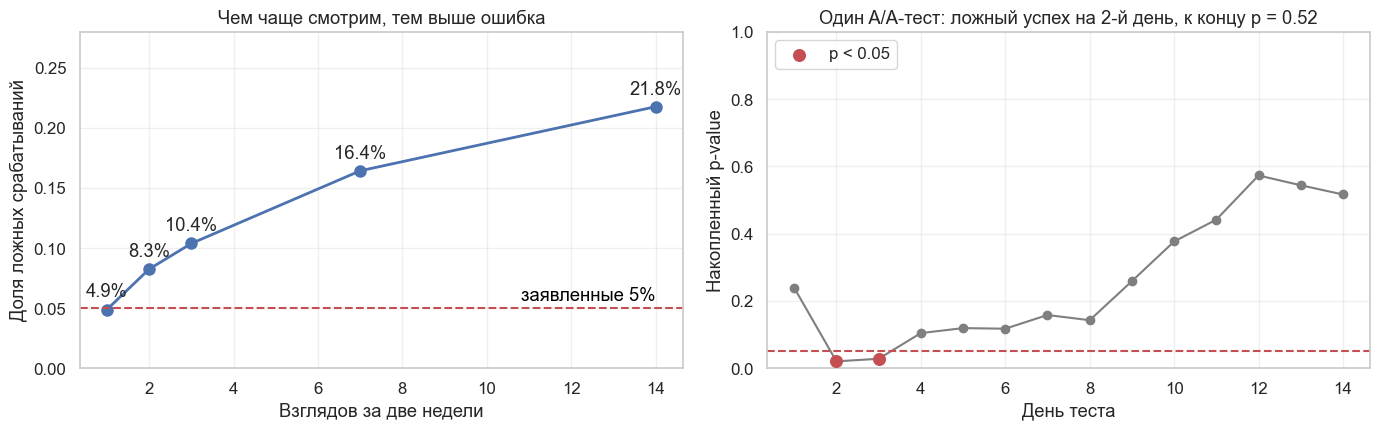

,1,2,3,7,14
Ложных срабатываний,0.049,0.083,0.104,0.164,0.218


In [6]:
schedules = {1: [14], 2: [7, 14], 3: [5, 10, 14], 7: [2, 4, 6, 8, 10, 12, 14], 14: list(range(1, 15))}
fpr_by_looks = pd.Series({k: peeking_fpr(days) for k, days in schedules.items()}, name="Ложных срабатываний")


def aa_pvalues(seed: int) -> np.ndarray:
    """Считает накопленный p-value одного A/A-теста по дням."""
    rng = np.random.default_rng(seed)
    x_a, x_b = (rng.binomial(N_DAY, P_BASE, PLAN_DAYS).cumsum() for _ in range(2))
    n = N_DAY * np.arange(1, PLAN_DAYS + 1)
    pool = (x_a + x_b) / (2 * n)
    z = (x_b - x_a) / n / np.sqrt(2 * pool * (1 - pool) / n)
    return 2 * stats.norm.sf(np.abs(z))


example = next(s for s in range(1000) if (aa_pvalues(s) < ALPHA).any() and aa_pvalues(s)[-1] > 0.5)
path = aa_pvalues(example)
first_hit = int(np.argmax(path < ALPHA)) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(fpr_by_looks.index, fpr_by_looks.values, "-o", color=BLUE, linewidth=2, markersize=8)
axes[0].axhline(ALPHA, color=RED, linestyle="--", linewidth=1.5)
axes[0].text(14, ALPHA + 0.006, "заявленные 5%", color="black", ha="right")
for k, v in fpr_by_looks.items():
    axes[0].annotate(f"{v:.1%}", (k, v), textcoords="offset points", xytext=(0, 9), ha="center")
axes[0].set(xlabel="Взглядов за две недели", ylabel="Доля ложных срабатываний", ylim=(0, 0.28),
            title="Чем чаще смотрим, тем выше ошибка")
days = np.arange(1, PLAN_DAYS + 1)
axes[1].plot(days, path, "-o", color=GRAY, linewidth=1.5)
axes[1].scatter(days[path < ALPHA], path[path < ALPHA], color=RED, s=70, zorder=3, label="p < 0.05")
axes[1].axhline(ALPHA, color=RED, linestyle="--", linewidth=1.5)
axes[1].set(xlabel="День теста", ylabel="Накопленный p-value", ylim=(0, 1),
            title=f"Один A/A-тест: ложный успех на {first_hit}-й день, к концу p = {path[-1]:.2f}")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

fpr_by_looks.to_frame().T

Обычный тест с ежедневными взглядами ошибается в 21.8% случаев вместо 5%: примерно один ложный запуск на пять тестов без эффекта, если решение принимается по первому «значимо». Даже два взгляда дают 8.3%. Справа видно, почему это коварно: тест был значим на 2-й и 3-й день, а к концу p-value равен 0.52. Команда, остановившаяся на 2-й день, никогда не узнала бы об этом.

**Вопрос.** Почему ошибка растёт всё медленнее с ростом числа взглядов, и почему 14 взглядов — это не 14 независимых шансов? Сколько дала бы поправка Бонферрони на 14 взглядов?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Накопленные статистики соседних дней сильно зависимы: корреляция между $Z_s$ и $Z_t$ равна $\sqrt{s/t}$. Новый взгляд добавляет мало новой информации, поэтому при 14 независимых проверках ошибка была бы $1 - 0.95^{14} \approx 51\%$, а реально 21.8%. По этой же причине Бонферрони здесь избыточен: порог $0.05 / 14$ считается для независимых проверок и в лекции уже показал потерю мощности. Границы GST учитывают зависимость точно, и этим займёмся дальше.

</details>

## 2. План GST

Выберем функцию расхода и посчитаем границы. Напомним из лекции: значение $\alpha(t)$ — это **накопленная** ошибка к доле данных $t$, а граница $b_i$ для $|Z|$ подбирается так, чтобы на взгляде $i$ потратить ровно прирост $\alpha(t_i) - \alpha(t_{i-1})$.

Функции расхода и генератор путей уже готовы.

In [7]:
norm = stats.norm


def obf_spending(t, alpha):
    """O'Brien-Fleming в форме Lan-DeMets."""
    return 2 * norm.sf(norm.ppf(1 - alpha / 2) / np.sqrt(t))


def pocock_spending(t, alpha):
    """Pocock в форме Lan-DeMets."""
    return alpha * np.log(1 + (np.e - 1) * t)


def null_paths(looks: np.ndarray, n_paths: int, seed: int = 11) -> np.ndarray:
    """Генерирует z-статистики в долях данных looks при верной H0."""
    rng = np.random.default_rng(seed)
    gaps = np.sqrt(np.diff(looks, prepend=0.0))
    walk = rng.standard_normal((n_paths, len(looks)), dtype=np.float32) * gaps
    return np.cumsum(walk, axis=1) / np.sqrt(looks)

### Задание 2. Границы

Реализуйте `gst_boundaries(spending, looks, alpha, n_paths, seed)`:

1. сгенерируйте `n_paths` нулевых путей функцией `null_paths`;
2. на взгляде $i$ среди ещё не остановившихся путей подберите границу как квантиль $|Z|$ так, чтобы за неё вышла доля $\alpha(t_i) - \alpha(t_{i-1})$ от **всех** путей;
3. если эта доля так мала, что на неё приходится меньше 100 путей, симуляция ненадёжна. Тогда берите границу аналитически: `norm.isf(step / 2)`, ведь при таких малых тратах взгляды почти независимы.

Функция возвращает массив границ.

In [8]:
def gst_boundaries(spending, looks, alpha: float = ALPHA_PRIMARY,
                   n_paths: int = 1_000_000, seed: int = 11) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError

In [9]:
# @title Решение (нажмите, чтобы раскрыть)
def gst_boundaries(spending, looks, alpha: float = ALPHA_PRIMARY,
                   n_paths: int = 1_000_000, seed: int = 11) -> np.ndarray:
    looks = np.asarray(looks, dtype=float)
    z = np.abs(null_paths(looks, n_paths, seed))
    alive = np.ones(n_paths, dtype=bool)
    spent, bounds = 0.0, []
    for i, t in enumerate(looks):
        step = float(spending(t, alpha)) - spent
        spent += step
        values = z[alive, i]
        k = int(step * n_paths)
        bound = np.partition(values, -k)[-k] if k >= 100 else norm.isf(step / 2)
        bounds.append(bound)
        alive[alive] = values < bound
    return np.array(bounds)

In [10]:
# Проверка: табличные границы при 5 равных взглядах и трате alpha / 2 на каждую сторону
reference = np.array([4.877, 3.357, 2.680, 2.290, 2.031])
five_looks = np.arange(1, 6) / 5
per_side = lambda t, a: 2 * obf_spending(t, a / 2)
ours = gst_boundaries(per_side, five_looks, alpha=0.05)
assert np.allclose(ours, reference, atol=0.03), f"Границы не совпали: {ours.round(3)}"

LOOKS = np.arange(1, PLAN_DAYS + 1) / PLAN_DAYS
BOUNDS_OBF = gst_boundaries(obf_spending, LOOKS)
BOUNDS_POCOCK = gst_boundaries(pocock_spending, LOOKS)

fpr_obf = (np.abs(null_paths(LOOKS, 1_000_000, seed=99)) >= BOUNDS_OBF).any(axis=1).mean()
fpr_pocock = (np.abs(null_paths(LOOKS, 1_000_000, seed=99)) >= BOUNDS_POCOCK).any(axis=1).mean()
assert abs(fpr_obf - ALPHA_PRIMARY) < 0.002 and abs(fpr_pocock - ALPHA_PRIMARY) < 0.002
print(f"Наши границы для K = 5: {ours.round(3)}")
print(f"Ложных срабатываний на новых путях: O'Brien-Fleming {fpr_obf:.4f}, Pocock {fpr_pocock:.4f} при цели {ALPHA_PRIMARY}")

Наши границы для K = 5: [4.877 3.358 2.682 2.291 2.031]
Ложных срабатываний на новых путях: O'Brien-Fleming 0.0246, Pocock 0.0245 при цели 0.025


Проверка сравнивает нас с табличными границами 4.877, 3.357, 2.680, 2.290, 2.031. Они относятся к варианту, где $\alpha/2$ тратится **на каждую сторону** отдельно, поэтому в проверке используется `per_side`. В лекции и в остальной части практики функция применяется сразу к $|Z|$, и первая граница при 5 взглядах равна 4.38. Оба варианта корректны и дают почти одно и то же, но при сверке с калькуляторами уточняйте, какая форма в них заложена.

### Задание 3. Запас выборки

В сравнении из лекции все методы шли с выборкой фиксированного теста, поэтому GST терял мощность. На практике максимальную выборку заранее увеличивают. Обозначим $R = N_{\max} / n_{\text{fixed}}$. Если эффект равен MDE, то в единицах нормированной статистики при $N_{\max}$ снос равен $(z_{1-\alpha/2} + z_{1-\beta})\sqrt{R}$, а путь на доле данных $t$ выглядит так:

$$
Z(t) = \frac{W(t) + \text{drift} \cdot t}{\sqrt{t}}
$$

Реализуйте две функции:

* `gst_power(boundaries, looks, drift, ...)` возвращает мощность и среднюю долю потраченной выборки. Если граница не пройдена, тест доходит до конца;
* `inflation_factor(boundaries, looks, alpha, power)` находит $R$, при котором мощность равна заданной. Используйте `scipy.optimize.brentq` на отрезке $[1, 1.6]$ и фиксированный `seed`: при общих случайных числах мощность монотонна по $R$.

In [11]:
def gst_power(boundaries, looks, drift: float, n_paths: int = 400_000, seed: int = 5) -> tuple:
    # ВАШ КОД
    raise NotImplementedError


def inflation_factor(boundaries, looks, alpha: float = ALPHA_PRIMARY, power: float = POWER) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [12]:
# @title Решение (нажмите, чтобы раскрыть)
def gst_power(boundaries, looks, drift: float, n_paths: int = 400_000, seed: int = 5) -> tuple:
    looks = np.asarray(looks, dtype=float)
    rng = np.random.default_rng(seed)
    gaps = np.diff(looks, prepend=0.0)
    walk = rng.standard_normal((n_paths, len(looks))) * np.sqrt(gaps) + drift * gaps
    z = np.cumsum(walk, axis=1) / np.sqrt(looks)
    hits = np.abs(z) >= boundaries
    fired = hits.any(axis=1)
    first = np.where(fired, hits.argmax(axis=1), len(looks) - 1)
    return float(fired.mean()), float(looks[first].mean())


def inflation_factor(boundaries, looks, alpha: float = ALPHA_PRIMARY, power: float = POWER) -> float:
    z_sum = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    return brentq(lambda r: gst_power(boundaries, looks, z_sum * np.sqrt(r))[0] - power, 1.0, 1.6, xtol=1e-3)

In [13]:
# Проверка: один взгляд в конце — это обычный тест, запас не нужен
single = np.array([1.0])
assert abs(inflation_factor(np.array([norm.ppf(1 - ALPHA_PRIMARY / 2)]), single) - 1) < 0.01

R_OBF = inflation_factor(BOUNDS_OBF, LOOKS)
R_POCOCK = inflation_factor(BOUNDS_POCOCK, LOOKS)
assert 1.0 < R_OBF < R_POCOCK < 1.4
print(f"Запас выборки: O'Brien-Fleming {R_OBF:.3f}, Pocock {R_POCOCK:.3f}")

Запас выборки: O'Brien-Fleming 1.049, Pocock 1.249


Соберём план: сколько нужно пользователей при каждом методе и сколько в среднем мы потратим.

In [14]:
def fixed_n(mde: float, p: float = P_BASE, alpha: float = ALPHA_PRIMARY, power: float = POWER) -> float:
    """Считает размер группы фиксированного теста для конверсии."""
    z_sum = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    return z_sum ** 2 * (p * (1 - p) + (p + mde) * (1 - p - mde)) / mde ** 2


n_fixed = fixed_n(MDE)
z_sum = norm.ppf(1 - ALPHA_PRIMARY / 2) + norm.ppf(POWER)
rows = {}
for name, bounds, r in [("Фиксированный тест", np.array([z_sum - norm.ppf(POWER)]), 1.0),
                        ("GST, O'Brien-Fleming", BOUNDS_OBF, R_OBF),
                        ("GST, Pocock", BOUNDS_POCOCK, R_POCOCK)]:
    grid = LOOKS if len(bounds) > 1 else np.array([1.0])
    shares = [gst_power(bounds, grid, z_sum * np.sqrt(r) * eff)[1] for eff in (0.0, 1.0, 1.5)]
    rows[name] = {"Запас R": r, "Nmax на группу": round(n_fixed * r), "Дней до Nmax": n_fixed * r / N_DAY,
                  "E[n] при H0, % от fixed": 100 * r * shares[0], "E[n] при MDE, % от fixed": 100 * r * shares[1],
                  "E[n] при 1.5 MDE, % от fixed": 100 * r * shares[2]}
plan = pd.DataFrame(rows).T
print(f"Фиксированный тест: {n_fixed:,.0f} на группу")
plan

Фиксированный тест: 37,821 на группу


,Запас R,Nmax на группу,Дней до Nmax,"E[n] при H0, % от fixed","E[n] при MDE, % от fixed","E[n] при 1.5 MDE, % от fixed"
Фиксированный тест,1.000,"37,821.000",12.607,100.000,100.000,100.000
"GST, O'Brien-Fleming",1.049,"39,666.000",13.222,104.392,79.218,56.187
"GST, Pocock",1.249,"47,241.000",15.747,123.245,79.331,45.229


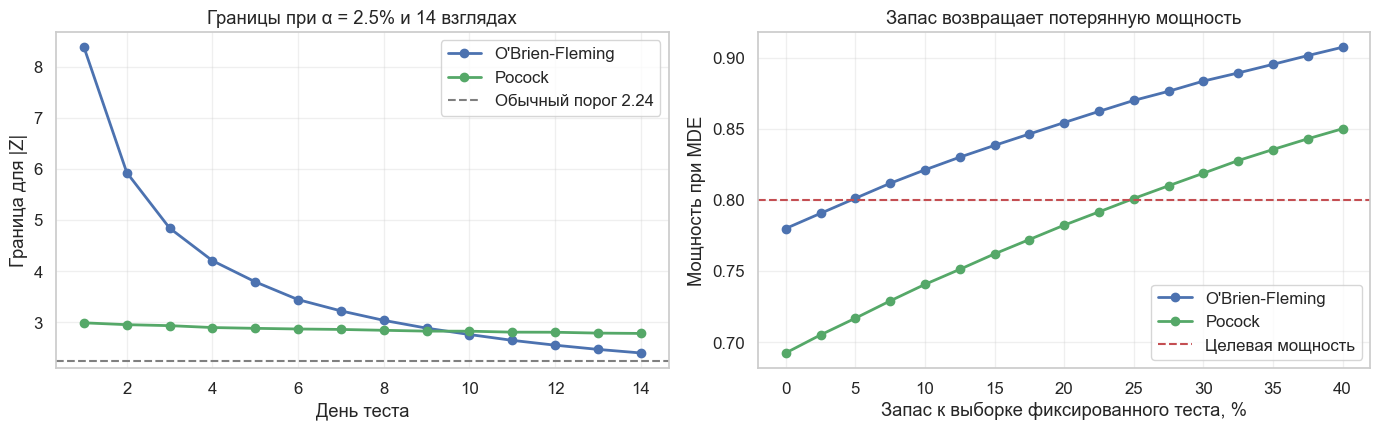

In [15]:
grid_r = np.linspace(1.0, 1.4, 17)
power_obf = [gst_power(BOUNDS_OBF, LOOKS, z_sum * np.sqrt(r), n_paths=100_000)[0] for r in grid_r]
power_pocock = [gst_power(BOUNDS_POCOCK, LOOKS, z_sum * np.sqrt(r), n_paths=100_000)[0] for r in grid_r]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
days = np.arange(1, PLAN_DAYS + 1)
axes[0].plot(days, BOUNDS_OBF, "-o", color=BLUE, linewidth=2, label="O'Brien-Fleming")
axes[0].plot(days, BOUNDS_POCOCK, "-o", color=GREEN, linewidth=2, label="Pocock")
axes[0].axhline(norm.ppf(1 - ALPHA_PRIMARY / 2), color=GRAY, linestyle="--", linewidth=1.5,
                label=f"Обычный порог {norm.ppf(1 - ALPHA_PRIMARY / 2):.2f}")
axes[0].set(xlabel="День теста", ylabel="Граница для |Z|", title="Границы при α = 2.5% и 14 взглядах")
axes[0].legend()
axes[1].plot(100 * (grid_r - 1), power_obf, "-o", color=BLUE, linewidth=2, label="O'Brien-Fleming")
axes[1].plot(100 * (grid_r - 1), power_pocock, "-o", color=GREEN, linewidth=2, label="Pocock")
axes[1].axhline(POWER, color=RED, linestyle="--", linewidth=1.5, label="Целевая мощность")
axes[1].set(xlabel="Запас к выборке фиксированного теста, %", ylabel="Мощность при MDE",
            title="Запас возвращает потерянную мощность")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

Что показывает таблица:

* **O'Brien–Fleming** просит запас всего около 5%, а в среднем при эффекте, равном MDE, тратит 79% выборки фиксированного теста.
* **Pocock** просит запас около 25%. При эффекте, равном MDE, выигрыша перед O'Brien–Fleming нет, он заметен только при эффекте 1.5 MDE: 45% против 56%.
* Плата за страховку есть всегда: если эффекта нет, O'Brien–Fleming потратит 104% фиксированной выборки, а Pocock 123%.

Выбираем **O'Brien–Fleming**. Выборку округляем вверх до целых недель (1.П2): 13.2 дня превращаются в 14, поэтому $N_{\max}$ = 42 000 на группу. Pocock потребовал бы 15.7 дня, то есть три недели.

In [16]:
N_MAX = PLAN_DAYS * N_DAY
power_plan = gst_power(BOUNDS_OBF, LOOKS, MDE / np.sqrt((P_BASE * (1 - P_BASE) + (P_BASE + MDE) * (1 - P_BASE - MDE)) / N_MAX))[0]
print(f"Nmax = {N_MAX:,} на группу, две полные недели. Мощность O'Brien-Fleming при MDE: {power_plan:.3f}")

Nmax = 42,000 на группу, две полные недели. Мощность O'Brien-Fleming при MDE: 0.824


## 3. mSPRT и выбор $\tau$

GST требует заранее зафиксировать $N_{\max}$. mSPRT этого не просит, но взамен просит параметр смеси $\tau$. Подготовим его для тех же данных.

Для произвольных размеров групп удобно записать формулы лекции через $V = \widehat{\mathrm{Var}}(\bar\Delta)$. При равных группах $V = 2\sigma^2 / n$, и получаются формулы лекции:

$$
\log\Lambda = \frac{1}{2}\log\frac{V}{V + \tau^2} + \frac{\bar\Delta^2 \tau^2}{2V(V + \tau^2)}, \qquad
r = \sqrt{\frac{2V(V + \tau^2)}{\tau^2}\left(\log\frac{1}{\alpha} + \frac{1}{2}\log\frac{V + \tau^2}{V}\right)}
$$

**Откуда взять $\tau$.** Интервал mSPRT шире обычного всегда, но при заданной выборке его ширина зависит от $\tau$. Выберем $\tau$ так, чтобы ширина была минимальна там, где мы рассчитываем принимать решение, то есть при плановом $V_{\text{план}}$. Приближённый ответ:

$$
\tau^2 \approx c \cdot V_{\text{план}}, \qquad c = -2\log\alpha + \log(1 - 2\log\alpha)
$$

Та же настройка используется в продакшене: в GrowthBook она записана как $\rho$ и параметр $N^*$.

### Задание 4. mSPRT

Реализуйте `msprt_log_lambda`, `msprt_radius`, `always_valid_p` и `tau_from_plan`. Always-valid p-value строится накопленным минимумом: $p_n = \min(p_{n-1}, 1 / \Lambda_n)$, $p_0 = 1$.

In [17]:
def msprt_log_lambda(diff, V, tau: float):
    # ВАШ КОД
    raise NotImplementedError


def msprt_radius(V, tau: float, alpha: float = ALPHA_PRIMARY):
    # ВАШ КОД
    raise NotImplementedError


def always_valid_p(diff, V, tau: float) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError


def tau_from_plan(V_plan: float, alpha: float = ALPHA_PRIMARY) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [18]:
# @title Решение (нажмите, чтобы раскрыть)
def msprt_log_lambda(diff, V, tau: float):
    return 0.5 * np.log(V / (V + tau ** 2)) + diff ** 2 * tau ** 2 / (2 * V * (V + tau ** 2))


def msprt_radius(V, tau: float, alpha: float = ALPHA_PRIMARY):
    return np.sqrt(2 * V * (V + tau ** 2) / tau ** 2 * (np.log(1 / alpha) + 0.5 * np.log((V + tau ** 2) / V)))


def always_valid_p(diff, V, tau: float) -> np.ndarray:
    return np.minimum.accumulate(np.minimum(1.0, np.exp(-msprt_log_lambda(diff, V, tau))))


def tau_from_plan(V_plan: float, alpha: float = ALPHA_PRIMARY) -> float:
    c = -2 * np.log(alpha) + np.log(-2 * np.log(alpha) + 1)
    return float(np.sqrt(c * V_plan))

In [19]:
# Проверка
V_test, tau_test = 2.5e-6, 0.005
r_test = msprt_radius(V_test, tau_test)
assert np.isclose(msprt_log_lambda(r_test, V_test, tau_test), np.log(1 / ALPHA_PRIMARY)), "Интервал не обращает тест"
assert np.all(np.diff(always_valid_p(np.array([0.0, 0.01, 0.0]), np.full(3, V_test), tau_test)) <= 0), "p-value не должен расти"

sigma2_diff = P_BASE * (1 - P_BASE) + (P_BASE + MDE) * (1 - P_BASE - MDE)
V_PLAN = sigma2_diff / N_MAX
TAU = tau_from_plan(V_PLAN)
tau_grid = np.geomspace(0.05, 20, 4000) * np.sqrt(V_PLAN)
tau_exact = tau_grid[np.argmin(msprt_radius(V_PLAN, tau_grid))]
print(f"tau по формуле: {TAU:.5f}, численный минимум ширины: {tau_exact:.5f}, MDE: {MDE}")
print(f"Отношение tau / MDE при n = n_fixed: {tau_from_plan(sigma2_diff / n_fixed) / MDE:.3f}")

tau по формуле: 0.00474, численный минимум ширины: 0.00481, MDE: 0.005
Отношение tau / MDE при n = n_fixed: 1.000


**Вопрос.** Посмотрите на последнюю строку вывода. Почему при $n = n_{\text{fixed}}$ получилось $\tau \approx$ MDE и откуда берётся правило лекции «$\tau$ близок к ожидаемому эффекту»?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Подставим $V_{\text{план}} = \sigma_\Delta^2 / n_{\text{fixed}}$, где $n_{\text{fixed}} = (z_{1-\alpha/2} + z_{1-\beta})^2 \sigma_\Delta^2 / \delta^2$. Получим

$$
\tau^2 \approx c \cdot \frac{\delta^2}{(z_{1-\alpha/2} + z_{1-\beta})^2}
$$

При $\alpha = 2.5\%$ и мощности 80% $c = 9.50$, а $(z_{1-\alpha/2} + z_{1-\beta})^2 = 9.50$, поэтому $\tau \approx \delta$. То же верно при $\alpha = 5\%$: 7.94 против 7.85. Это совпадение обычных значений $\alpha$ и $\beta$, а не закон, но оно объясняет, почему правило работает: выбрать $\tau$, равный MDE, значит настроить тест на выборку фиксированного теста.

</details>

Теперь посмотрим, сколько стоит ошибка в $\tau$ и как mSPRT выглядит рядом с GST.

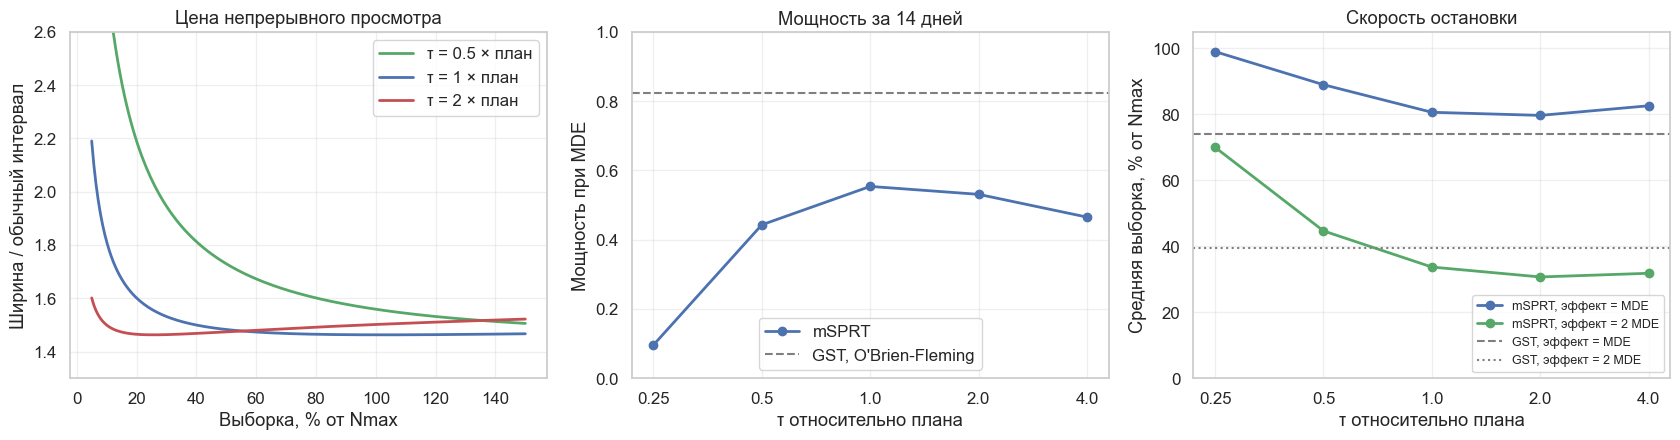

GST при MDE: мощность 0.824, средняя выборка 74.1% от Nmax


,Мощность при MDE,Доля выборки при MDE,Доля выборки при 2 MDE,Ложных срабатываний
τ / τ по плану,,,,
0.250,0.096,0.990,0.700,0.000
0.500,0.443,0.890,0.447,0.001
1.000,0.554,0.806,0.337,0.005
2.000,0.531,0.797,0.307,0.006
4.000,0.465,0.826,0.318,0.005


In [20]:
def msprt_operating(tau: float, drift: float, n_paths: int = 300_000, seed: int = 5, days: int = PLAN_DAYS) -> tuple:
    """Оценивает мощность и долю потраченной выборки mSPRT с ежедневными взглядами до Nmax."""
    t = np.arange(1, days + 1) / PLAN_DAYS
    rng = np.random.default_rng(seed)
    gaps = np.diff(t, prepend=0.0)
    diff = np.cumsum(rng.standard_normal((n_paths, days)) * np.sqrt(gaps) + drift * gaps, axis=1) / t
    hits = msprt_log_lambda(diff, 1 / t, tau) >= np.log(1 / ALPHA_PRIMARY)
    fired = hits.any(axis=1)
    return float(fired.mean()), float(t[np.where(fired, hits.argmax(axis=1), days - 1)].mean())


drift_mde = MDE / np.sqrt(V_PLAN)
tau_ratios = np.array([0.25, 0.5, 1, 2, 4])
operating = pd.DataFrame({ratio: {"Мощность при MDE": msprt_operating(ratio * TAU / np.sqrt(V_PLAN), drift_mde)[0],
                                  "Доля выборки при MDE": msprt_operating(ratio * TAU / np.sqrt(V_PLAN), drift_mde)[1],
                                  "Доля выборки при 2 MDE": msprt_operating(ratio * TAU / np.sqrt(V_PLAN), 2 * drift_mde)[1],
                                  "Ложных срабатываний": msprt_operating(ratio * TAU / np.sqrt(V_PLAN), 0.0)[0]}
                          for ratio in tau_ratios}).T
operating.index.name = "τ / τ по плану"

gst_power_mde, gst_share_mde = gst_power(BOUNDS_OBF, LOOKS, drift_mde)
gst_share_2 = gst_power(BOUNDS_OBF, LOOKS, 2 * drift_mde)[1]

share = np.linspace(0.05, 1.5, 200)
V_curve = V_PLAN / share
fixed_radius = norm.ppf(1 - ALPHA_PRIMARY / 2) * np.sqrt(V_curve)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ratio, color in [(0.5, GREEN), (1, BLUE), (2, RED)]:
    axes[0].plot(share * 100, msprt_radius(V_curve, ratio * TAU) / fixed_radius, color=color, linewidth=2, label=f"τ = {ratio} × план")
axes[0].set(xlabel="Выборка, % от Nmax", ylabel="Ширина / обычный интервал", ylim=(1.3, 2.6),
            title="Цена непрерывного просмотра")
axes[0].legend()
axes[1].plot(tau_ratios, operating["Мощность при MDE"], "-o", color=BLUE, linewidth=2, label="mSPRT")
axes[1].axhline(gst_power_mde, color=GRAY, linestyle="--", linewidth=1.5, label="GST, O'Brien-Fleming")
axes[1].set(xscale="log", xticks=tau_ratios, xticklabels=tau_ratios, xlabel="τ относительно плана",
            ylabel="Мощность при MDE", ylim=(0, 1), title="Мощность за 14 дней")
axes[1].legend(loc="lower center")
axes[2].plot(tau_ratios, 100 * operating["Доля выборки при MDE"], "-o", color=BLUE, linewidth=2, label="mSPRT, эффект = MDE")
axes[2].plot(tau_ratios, 100 * operating["Доля выборки при 2 MDE"], "-o", color=GREEN, linewidth=2, label="mSPRT, эффект = 2 MDE")
axes[2].axhline(100 * gst_share_mde, color=GRAY, linestyle="--", linewidth=1.5, label="GST, эффект = MDE")
axes[2].axhline(100 * gst_share_2, color=GRAY, linestyle=":", linewidth=1.5, label="GST, эффект = 2 MDE")
axes[2].set(xscale="log", xticks=tau_ratios, xticklabels=tau_ratios, xlabel="τ относительно плана",
            ylabel="Средняя выборка, % от Nmax", ylim=(0, 105), title="Скорость остановки")
axes[2].legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

print(f"GST при MDE: мощность {gst_power_mde:.3f}, средняя выборка {gst_share_mde:.1%} от Nmax")
operating

Что видно на графиках:

* **Слева.** Ширина минимальна около планового объёма и равна примерно 1.46 обычного интервала. Эту цену нельзя убрать настройкой, а можно только выбрать, на какой объём её оптимизировать.
* **В центре.** Лучшая мощность при $\tau$ около плана, но она равна 55% против 82% у GST на той же выборке. Занижать $\tau$ вчетверо опасно: мощность падает до 10%. Завышать намного безопаснее.
* **Справа.** При сильном эффекте mSPRT останавливается раньше GST: 34% выборки против 40% при эффекте 2 MDE. При эффекте, равном MDE, GST быстрее: 74% против 81%.

В последней колонке таблицы доля ложных срабатываний 0.5% при заявленных 2.5%: гарантия рассчитана на просмотр после каждого наблюдения, а мы смотрим раз в день. Это причина потери мощности, а не ошибка в реализации.

## 4. Выручка и тяжёлый хвост

Вторая основная метрика устроена иначе. Из истории известно: конверсия 5%, стоимость брони логнормальна с медианой 12 000 ₽ и $\sigma = 1.2$. Правило Кохави и соавторов для скошенных метрик: чтобы среднее было близко к нормальному, в группе нужно хотя бы $355 \cdot s^2$ наблюдений, где $s$ — коэффициент асимметрии.

Заодно применим **капирование**: все значения выше порога заменяем порогом. Порог берём по истории и **фиксируем до запуска**: 99-й перцентиль стоимости брони. Если выбирать порог по данным теста, правило обработки начнёт зависеть от результата.

### Задание 5. Скошенность

Реализуйте `skewness(x)` и `min_n_clt(x)`.

In [21]:
def skewness(x) -> float:
    # ВАШ КОД
    raise NotImplementedError


def min_n_clt(x) -> int:
    # ВАШ КОД
    raise NotImplementedError

In [22]:
# @title Решение (нажмите, чтобы раскрыть)
def skewness(x) -> float:
    x = np.asarray(x, dtype=float)
    centered = x - x.mean()
    return float((centered ** 3).mean() / (centered ** 2).mean() ** 1.5)


def min_n_clt(x) -> int:
    return int(np.ceil(355 * skewness(x) ** 2))

In [23]:
# Проверка
CHECK_MEDIAN, CHECK_SIGMA = 12_000, 1.2
CAP = float(np.round(stats.lognorm.ppf(0.99, CHECK_SIGMA, scale=CHECK_MEDIAN), -3))


def history_revenue(n: int, seed: int = 7) -> np.ndarray:
    """Генерирует выручку на пользователя до теста."""
    rng = np.random.default_rng(seed)
    booked = rng.random(n) < P_BASE
    return booked * rng.lognormal(np.log(CHECK_MEDIAN), CHECK_SIGMA, n)


revenue_hist = history_revenue(3_000_000)
capped_hist = np.minimum(revenue_hist, CAP)
assert np.isclose(skewness(revenue_hist), stats.skew(revenue_hist))

summary = pd.DataFrame({
    "Как есть": {"ARPU, ₽": revenue_hist.mean(), "Стд. откл., ₽": revenue_hist.std(), "Скошенность": skewness(revenue_hist), "355·s² на группу": min_n_clt(revenue_hist)},
    f"С порогом {CAP:,.0f} ₽": {"ARPU, ₽": capped_hist.mean(), "Стд. откл., ₽": capped_hist.std(), "Скошенность": skewness(capped_hist), "355·s² на группу": min_n_clt(capped_hist)},
}).T
summary

,"ARPU, ₽","Стд. откл., ₽",Скошенность,355·s² на группу
Как есть,"1,234.664","11,319.500",35.351,"443,631.000"
"С порогом 196,000 ₽","1,171.041","8,890.118",13.343,"63,205.000"


Правило требует 443 тысячи пользователей на группу, а у нас будет 42 тысячи. Даже с порогом нужно 63 тысячи. Выходит, нормальное приближение здесь не работает и выбросы будут ложно останавливать тест?

**Вопрос.** Запишите свой прогноз: что случится с z-статистикой, если в группу B попала одна гигантская бронь, настолько большая, что она определяет и среднее, и дисперсию группы?

Проверим на симуляции. Для каждого сочетания трафика, сплита и обработки выручки запускаем 2 000 A/A-тестов с 14 взглядами и считаем ложные срабатывания при заявленных 2.5%.

In [24]:
def revenue_paths(users_per_day: int, share_b: float, cap: float = None, R: int = 2000, seed: int = 3) -> tuple:
    """Генерирует A/A-тесты на выручке и возвращает накопленные разность средних и дисперсию разности."""
    rng = np.random.default_rng(seed)
    days = np.arange(PLAN_DAYS)
    n_groups = np.array([users_per_day * (1 - share_b), users_per_day * share_b]).round().astype(int)
    sums = np.zeros((R, 2, PLAN_DAYS, 2))
    for sim in range(R):
        for g, n in enumerate(n_groups):
            buyers = rng.binomial(n, P_BASE, PLAN_DAYS)
            x = rng.lognormal(np.log(CHECK_MEDIAN), CHECK_SIGMA, buyers.sum())
            x = np.minimum(x, cap) if cap else x
            index = np.repeat(days, buyers)
            sums[sim, g, :, 0] = np.bincount(index, x, PLAN_DAYS)
            sums[sim, g, :, 1] = np.bincount(index, x ** 2, PLAN_DAYS)
    totals = sums.cumsum(axis=2)
    n = (days + 1)[None, :] * n_groups[:, None]
    means = totals[:, :, :, 0] / n
    variances = (totals[:, :, :, 1] / n - means ** 2) / n
    return means[:, 1] - means[:, 0], variances.sum(axis=1)


rows = []
for users in (300, 6_000):
    for share_b in (0.5, 0.2):
        for cap, cap_name in ((None, "Как есть"), (CAP, "С порогом")):
            diff, V = revenue_paths(users, share_b, cap)
            with np.errstate(divide="ignore", invalid="ignore"):
                z = np.where(V > 0, diff / np.sqrt(V), 0.0)
            tau = tau_from_plan(V[:, -1].mean())
            positive = np.maximum(V, 1e-12)
            rows.append({"Трафик в день": users, "Доля B": share_b, "Выручка": cap_name,
                         "GST": (np.abs(z) >= BOUNDS_OBF).any(axis=1).mean(),
                         "mSPRT": (msprt_log_lambda(diff, positive, tau) >= np.log(1 / ALPHA_PRIMARY)).any(axis=1).mean()})
aa_revenue = pd.DataFrame(rows)
aa_revenue

,Трафик в день,Доля B,Выручка,GST,mSPRT
0,300,0.500,Как есть,0.015,0.001
1,300,0.500,С порогом,0.021,0.002
2,300,0.200,Как есть,0.060,0.028
3,300,0.200,С порогом,0.062,0.033
4,6000,0.500,Как есть,0.023,0.004
5,6000,0.500,С порогом,0.025,0.004
6,6000,0.200,Как есть,0.025,0.018
7,6000,0.200,С порогом,0.024,0.011


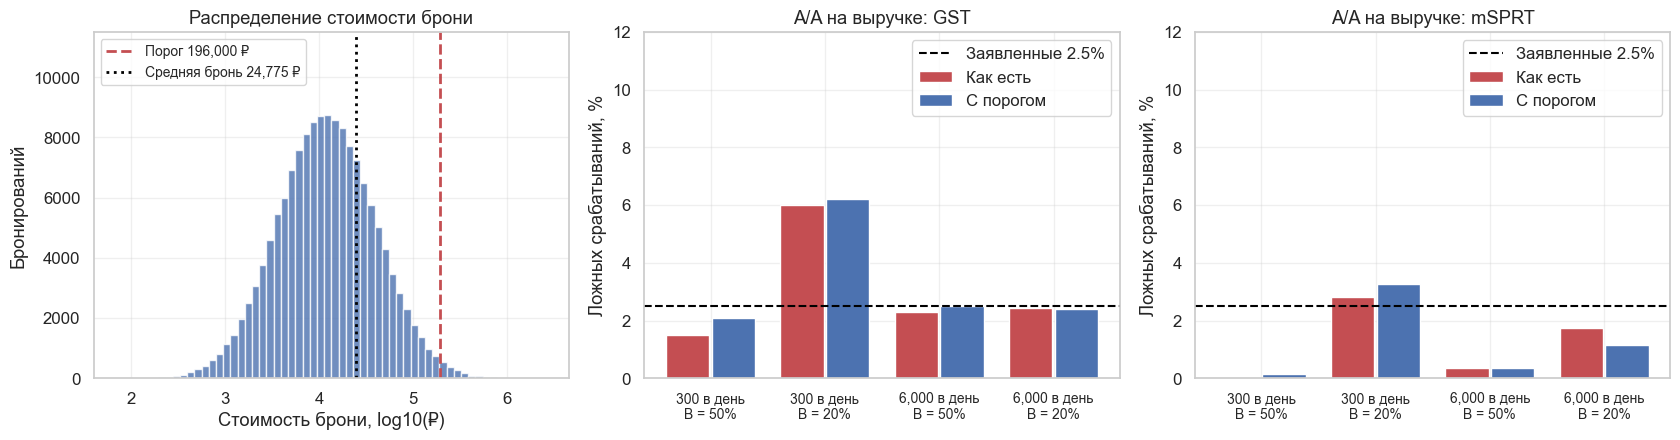

In [25]:
booked_hist = revenue_hist[revenue_hist > 0]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].hist(np.log10(booked_hist), bins=60, color=BLUE, alpha=0.8)
axes[0].axvline(np.log10(CAP), color=RED, linestyle="--", linewidth=2, label=f"Порог {CAP:,.0f} ₽")
axes[0].axvline(np.log10(booked_hist.mean()), color="black", linestyle=":", linewidth=2, label=f"Средняя бронь {booked_hist.mean():,.0f} ₽")
axes[0].set(xlabel="Стоимость брони, log10(₽)", ylabel="Бронирований", ylim=(0, 11_500), title="Распределение стоимости брони")
axes[0].legend(loc="upper left", fontsize=10)

for ax, method in zip(axes[1:], ("GST", "mSPRT")):
    pivot = aa_revenue.assign(setting=lambda d: d["Трафик в день"].map("{:,} в день".format) + "\nB = " + (100 * d["Доля B"]).astype(int).astype(str) + "%")
    settings = list(dict.fromkeys(pivot["setting"]))
    x = np.arange(len(settings))
    raw = pivot[pivot["Выручка"] == "Как есть"].set_index("setting").loc[settings, method]
    cut = pivot[pivot["Выручка"] == "С порогом"].set_index("setting").loc[settings, method]
    ax.bar(x - 0.2, 100 * raw, width=0.38, color=RED, label="Как есть")
    ax.bar(x + 0.2, 100 * cut, width=0.38, color=BLUE, label="С порогом")
    ax.axhline(100 * ALPHA_PRIMARY, color="black", linestyle="--", linewidth=1.5, label="Заявленные 2.5%")
    ax.set_xticks(x, settings, fontsize=10)
    ax.set(ylabel="Ложных срабатываний, %", title=f"A/A на выручке: {method}", ylim=(0, 12))
    ax.legend()
plt.tight_layout()
plt.show()

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Пусть в группе из $n$ человек одна бронь $X$ намного больше всего остального. Тогда разность средних примерно равна $X / n$, а дисперсия этой разности примерно равна $X^2 / n^2$. Получаем $|z| \approx 1$: выброс раздувает собственный знаменатель. Сам по себе он **не может** перейти границу, поэтому рассуждение «один выброс вызвал ложную остановку» при оценке дисперсии по данным не работает.

</details>

Что показывают столбцы:

* **Сплит 50/50.** Ошибка не выше заявленной даже при 300 пользователях в день: асимметрия двух одинаковых групп взаимно гасится в разности средних, а правило $355 s^2$ относится к одному среднему.
* **Сплит 80/20 при малом трафике.** GST даёт 6% вместо 2.5%: малая группа скошена сильнее большой, и в разности асимметрия уже не гасится. Порог по 99-му перцентилю тут не помогает, потому что у 60 пользователей в день за 14 дней набирается всего около 40 броней.
* **Наш трафик.** При 6 000 пользователей в день ошибка держится на заявленном уровне при обоих сплитах.

Итог: опасно не «наличие хвоста», а **неравный сплит и малая выборка**. mSPRT здесь заметно осторожнее GST, но и он при 300 пользователях и сплите 80/20 слегка выходит за 2.5%.

Зачем тогда порог, если ошибка в порядке? Ради мощности.

### Задание 6. Чувствительность

Реализуйте `revenue_mde(sigma, n_group, ...)`: абсолютный MDE теста на среднее при известной дисперсии и равных группах. Формула та же, что для размера выборки, только решённая относительно эффекта.

In [26]:
def revenue_mde(sigma: float, n_group: int, alpha: float = ALPHA_PRIMARY, power: float = POWER) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [27]:
# @title Решение (нажмите, чтобы раскрыть)
def revenue_mde(sigma: float, n_group: int, alpha: float = ALPHA_PRIMARY, power: float = POWER) -> float:
    return (norm.ppf(1 - alpha / 2) + norm.ppf(power)) * np.sqrt(2 * sigma ** 2 / n_group)

In [28]:
# Проверка: при MDE из формулы фиксированный тест даёт заложенную мощность
check_mde = revenue_mde(1.0, 10_000)
assert np.isclose(norm.cdf(check_mde / np.sqrt(2 / 10_000) - norm.ppf(1 - ALPHA_PRIMARY / 2)), POWER)

sens = pd.DataFrame({name: {"MDE, ₽": revenue_mde(x.std(), N_MAX), "MDE, % от ARPU": 100 * revenue_mde(x.std(), N_MAX) / x.mean(),
                            "Пользователей на группу для 10%": 2 * z_sum ** 2 * x.var() / (0.1 * x.mean()) ** 2}
                     for name, x in [("Как есть", revenue_hist), ("С порогом", capped_hist)]}).T
sens

,"MDE, ₽","MDE, % от ARPU",Пользователей на группу для 10%
Как есть,240.821,19.505,"159,786.819"
С порогом,189.136,16.151,"109,560.720"


Без порога тест за две недели замечает только эффект от 19.5% ARPU, с порогом от 16.2%. Порог дешёвый и полезный, но оценивает он уже другое: эффект на **капированную** выручку, и в отчёте это нужно писать прямо.

**Важный итог для плана.** $N_{\max}$ у нас задан конверсией и бюджетом времени, а для выручки его мало. Чтобы замечать 10% ARPU, нужно 110 тысяч пользователей на группу, то есть 37 дней. Значит, на выручке значимый результат за две недели увидим только при очень сильном эффекте. Заранее сообщаем об этом продакту: незначимая выручка в этом тесте не означает, что эффекта нет.

## 5. Прогон логов по дням

Из-за заморозки релизов блок проработал не две недели, а **четыре**, поэтому в логе есть данные дальше плана. Это удачно: сначала сыграем тест так, как он шёл бы в реальности, день за днём и только на **первых 14 днях**. А дни 15–28 откроем в разделе 7.

Данные синтетические, их генерирует скрипт [`data/generate_data.py`](data/generate_data.py). Истинные эффекты зашиты в нём, не подглядывайте до раздела 7.

| Колонка | Смысл |
|---|---|
| `user_id` | идентификатор пользователя |
| `date` | день первого захода |
| `group` | A — без блока, B — с блоком |
| `booked` | сделал ли бронирование (0/1) |
| `revenue` | стоимость бронирования, ₽ (0, если брони нет) |
| `cancelled` | отменил ли бронирование (0/1) |

In [29]:
LOCAL_PATH = Path("data/hotdeals_ab.csv")
REPO_PATH = "2. Квази-эксперименты/Практический блок/01. Последовательное тестирование/data/hotdeals_ab.csv"
DATA_URL = "https://raw.githubusercontent.com/Alberelloo/Hypothesis-Testing-Course/main/" + quote(REPO_PATH)

logs = pd.read_csv(LOCAL_PATH if LOCAL_PATH.exists() else DATA_URL, parse_dates=["date"])
logs["day"] = (logs["date"] - logs["date"].min()).dt.days + 1
logs["revenue_capped"] = logs["revenue"].clip(upper=CAP)
print(logs.shape, f"период: {logs['date'].min():%Y-%m-%d} — {logs['date'].max():%Y-%m-%d}")

plan_logs = logs[logs["day"] <= PLAN_DAYS]
counts = plan_logs["group"].value_counts().reindex(["A", "B"])
srm_p = stats.chisquare(counts).pvalue
print(f"A: {counts['A']:,}, B: {counts['B']:,}, SRM p-value = {srm_p:.3f}")
plan_logs.head()

(167861, 8) период: 2026-09-07 — 2026-10-04
A: 42,300, B: 41,862, SRM p-value = 0.131


,user_id,date,group,booked,revenue,cancelled,day,revenue_capped
0,100000,2026-09-07,B,0,0,0,1,0
1,100001,2026-09-07,A,0,0,0,1,0
2,100002,2026-09-07,B,0,0,0,1,0
3,100003,2026-09-07,A,0,0,0,1,0
4,100004,2026-09-07,A,0,0,0,1,0


SRM нет, сплит держится. Теперь логи надо превратить в накопленные итоги.

### Задание 7. Накопленные итоги

Реализуйте `daily_cumulative(df, metric)`. Функция возвращает таблицу с индексом по дню и колонками `n_a`, `n_b`, `mean_a`, `mean_b`, `diff`, `V`. Все значения считаются **накопленным итогом** с начала теста, а `V` — это $\hat\sigma_A^2 / n_A + \hat\sigma_B^2 / n_B$.

In [30]:
def daily_cumulative(df: pd.DataFrame, metric: str) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [31]:
# @title Решение (нажмите, чтобы раскрыть)
def daily_cumulative(df: pd.DataFrame, metric: str) -> pd.DataFrame:
    grouped = (df.assign(square=df[metric] ** 2).groupby(["day", "group"])
               .agg(n=(metric, "size"), total=(metric, "sum"), squares=("square", "sum")).unstack().cumsum())
    n_a, n_b = grouped[("n", "A")], grouped[("n", "B")]
    mean_a, mean_b = grouped[("total", "A")] / n_a, grouped[("total", "B")] / n_b
    var_a = grouped[("squares", "A")] / n_a - mean_a ** 2
    var_b = grouped[("squares", "B")] / n_b - mean_b ** 2
    return pd.DataFrame({"n_a": n_a, "n_b": n_b, "mean_a": mean_a, "mean_b": mean_b,
                         "diff": mean_b - mean_a, "V": var_a / n_a + var_b / n_b})

In [32]:
# Проверка
cum_conv = daily_cumulative(plan_logs, "booked")
last = plan_logs.groupby("group")["booked"]
assert np.isclose(cum_conv["diff"].iloc[-1], last.mean()["B"] - last.mean()["A"])
expected_V = (last.var(ddof=0) / last.size()).sum()
assert np.isclose(cum_conv["V"].iloc[-1], expected_V)
cum_conv[["n_a", "n_b", "mean_a", "mean_b", "diff"]].tail(3)

,n_a,n_b,mean_a,mean_b,diff
day,,,,,
12,35200,34854,0.052,0.057,0.005
13,38710,38340,0.052,0.057,0.005
14,42300,41862,0.052,0.057,0.005


### Задание 8. Прогон

Реализуйте две функции. Обе дописывают к таблице колонки `radius` (полуширина интервала на этот день) и `crossed` (сработал ли критерий).

* `replay_gst(cum, spending, n_max, alpha)`. Доля данных берётся **фактическая**: $(n_A + n_B) / (2 N_{\max})$. Трафик в выходные выше, поэтому дни не равны. Последний взгляд считаем долей 1, чтобы потратить весь остаток $\alpha$. Границы считаем заново по этим долям, это и есть гибкость подхода Lan–DeMets. Колонки: `share`, `z`, `bound`, `radius` = $b_i \sqrt{V}$, `crossed`.
* `replay_msprt(cum, tau, alpha)`. Колонки: `p_always`, `radius`, `crossed`.

Контрольную метрику проверяем на рост: доверительная последовательность уровня 10% даёт одностороннюю гарантию 5%, а тревогой считаем нижнюю границу выше нуля.

In [33]:
def replay_gst(cum: pd.DataFrame, spending, n_max: int = N_MAX, alpha: float = ALPHA_PRIMARY) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError


def replay_msprt(cum: pd.DataFrame, tau: float, alpha: float = ALPHA_PRIMARY) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [34]:
# @title Решение (нажмите, чтобы раскрыть)
def replay_gst(cum: pd.DataFrame, spending, n_max: int = N_MAX, alpha: float = ALPHA_PRIMARY) -> pd.DataFrame:
    share = ((cum["n_a"] + cum["n_b"]) / (2 * n_max)).clip(upper=1).to_numpy()
    share[-1] = 1.0                  # на последнем взгляде тратим весь остаток alpha
    bounds = gst_boundaries(spending, share, alpha)
    z = (cum["diff"] / np.sqrt(cum["V"])).to_numpy()
    return cum.assign(share=share, z=z, bound=bounds, radius=bounds * np.sqrt(cum["V"]), crossed=np.abs(z) >= bounds)


def replay_msprt(cum: pd.DataFrame, tau: float, alpha: float = ALPHA_PRIMARY) -> pd.DataFrame:
    pvalue = always_valid_p(cum["diff"].to_numpy(), cum["V"].to_numpy(), tau)
    return cum.assign(p_always=pvalue, radius=msprt_radius(cum["V"], tau, alpha), crossed=pvalue <= alpha)

In [35]:
# Проверка
gst_conv = replay_gst(cum_conv, obf_spending)
msprt_conv = replay_msprt(cum_conv, TAU)
assert gst_conv["bound"].is_monotonic_decreasing, "Границы O'Brien-Fleming должны снижаться"
assert (msprt_conv["p_always"].diff().dropna() <= 0).all()
assert (msprt_conv["crossed"] == (msprt_conv["diff"].abs() > msprt_conv["radius"])).iloc[msprt_conv["crossed"].argmax()]


def first_day(result: pd.DataFrame):
    """Возвращает первый день срабатывания."""
    return int(result.index[result["crossed"].argmax()]) if result["crossed"].any() else None


def summarize(name: str, method: str, result: pd.DataFrame, scale: float) -> dict:
    """Собирает строку отчёта о первом срабатывании."""
    day = first_day(result)
    row = result.loc[day] if day else result.iloc[-1]
    return {"Метрика": name, "Метод": method, "День остановки": day or "нет",
            "Оценка": row["diff"] * scale, "Нижняя граница": (row["diff"] - row["radius"]) * scale,
            "Верхняя граница": (row["diff"] + row["radius"]) * scale}


cum_rev = daily_cumulative(plan_logs, "revenue_capped")
V_rev_plan = 2 * capped_hist.var() / N_MAX
TAU_REV = tau_from_plan(V_rev_plan)
gst_rev = replay_gst(cum_rev, obf_spending)
msprt_rev = replay_msprt(cum_rev, TAU_REV)

cum_cancel = daily_cumulative(plan_logs, "cancelled")
P_CANCEL = 0.009             # доля пользователей с отменой до теста
V_cancel_plan = 2 * P_CANCEL * (1 - P_CANCEL) / N_MAX
TAU_CANCEL = tau_from_plan(V_cancel_plan, alpha=2 * ALPHA)
msprt_cancel = replay_msprt(cum_cancel, TAU_CANCEL, alpha=2 * ALPHA)
msprt_cancel["crossed"] = msprt_cancel["diff"] - msprt_cancel["radius"] > 0

replay = pd.DataFrame([summarize("Конверсия, п.п.", "GST", gst_conv, 100),
                       summarize("Конверсия, п.п.", "mSPRT", msprt_conv, 100),
                       summarize("Выручка с порогом, ₽", "GST", gst_rev, 1),
                       summarize("Выручка с порогом, ₽", "mSPRT", msprt_rev, 1),
                       summarize("Отмены, п.п.", "mSPRT, рост", msprt_cancel, 100)])
replay

,Метрика,Метод,День остановки,Оценка,Нижняя граница,Верхняя граница
0,"Конверсия, п.п.",GST,6,0.939,0.082,1.797
1,"Конверсия, п.п.",mSPRT,2,1.740,0.051,3.429
2,"Выручка с порогом, ₽",GST,нет,91.788,-64.659,248.235
3,"Выручка с порогом, ₽",mSPRT,нет,91.788,-123.235,306.811
4,"Отмены, п.п.","mSPRT, рост",нет,0.149,-0.044,0.341


Посмотрим на прогон глазами продакта, который открывает дашборд каждый день.

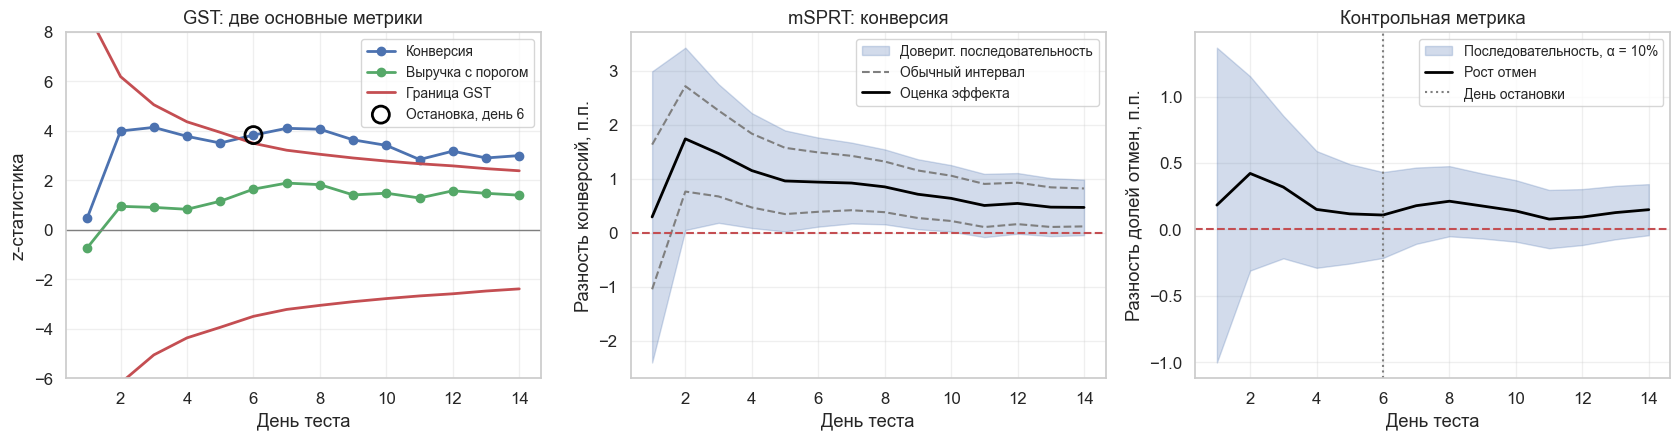

,share,diff,z,bound
day,,,,
5,0.329,0.010,3.509,3.941
6,0.414,0.009,3.830,3.497
7,0.499,0.009,4.104,3.218


In [36]:
stop_day = first_day(gst_conv)
days = gst_conv.index

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(days, gst_conv["z"], "-o", color=BLUE, linewidth=2, label="Конверсия")
axes[0].plot(days, gst_rev["z"], "-o", color=GREEN, linewidth=2, label="Выручка с порогом")
axes[0].plot(days, gst_conv["bound"], "-", color=RED, linewidth=2, label="Граница GST")
axes[0].plot(days, -gst_conv["bound"], "-", color=RED, linewidth=2)
axes[0].axhline(0, color=GRAY, linewidth=1)
axes[0].scatter([stop_day], [gst_conv.loc[stop_day, "z"]], s=150, facecolor="none", edgecolor="black", linewidth=2, zorder=4, label=f"Остановка, день {stop_day}")
axes[0].set(xlabel="День теста", ylabel="z-статистика", ylim=(-6, 8), title="GST: две основные метрики")
axes[0].legend(fontsize=10, loc="upper right")

fixed = norm.ppf(1 - ALPHA_PRIMARY / 2) * np.sqrt(msprt_conv["V"])
axes[1].fill_between(days, 100 * (msprt_conv["diff"] - msprt_conv["radius"]), 100 * (msprt_conv["diff"] + msprt_conv["radius"]), color=BLUE, alpha=0.25, label="Доверит. последовательность")
axes[1].plot(days, 100 * (msprt_conv["diff"] - fixed), color=GRAY, linestyle="--", linewidth=1.5, label="Обычный интервал")
axes[1].plot(days, 100 * (msprt_conv["diff"] + fixed), color=GRAY, linestyle="--", linewidth=1.5)
axes[1].plot(days, 100 * msprt_conv["diff"], color="black", linewidth=2, label="Оценка эффекта")
axes[1].axhline(0, color=RED, linestyle="--", linewidth=1.5)
axes[1].set(xlabel="День теста", ylabel="Разность конверсий, п.п.", title="mSPRT: конверсия")
axes[1].legend(fontsize=10)

axes[2].fill_between(days, 100 * (msprt_cancel["diff"] - msprt_cancel["radius"]), 100 * (msprt_cancel["diff"] + msprt_cancel["radius"]), color=BLUE, alpha=0.25, label="Последовательность, α = 10%")
axes[2].plot(days, 100 * msprt_cancel["diff"], color="black", linewidth=2, label="Рост отмен")
axes[2].axhline(0, color=RED, linestyle="--", linewidth=1.5)
axes[2].axvline(stop_day, color=GRAY, linestyle=":", linewidth=1.5, label="День остановки")
axes[2].set(xlabel="День теста", ylabel="Разность долей отмен, п.п.", title="Контрольная метрика")
axes[2].legend(fontsize=10)
plt.tight_layout()
plt.show()

gst_conv.loc[[stop_day - 1, stop_day, stop_day + 1], ["share", "diff", "z", "bound"]]

На 6-й день конверсия пересекла границу GST: $z = 3.83$ при границе 3.50. Оценка **+0.94 п.п.**, почти вдвое выше MDE. mSPRT сработал ещё раньше, на 2-й день, с оценкой +1.74 п.п. Выручка и отмены значимо не изменились. По правилу решения всё выполнено: основная метрика выросла, контрольная не ухудшилась.

Продакт пишет: «Конверсия +18%, раскатываем на всех!». Формально всё честно: метод корректный, $\alpha$ под контролем.

**Вопрос.** Что бы вы проверили, прежде чем соглашаться? Запишите ответ, а следующие два раздела покажут, что здесь не так.

## 6. Завышение эффекта при ранней остановке

Последовательный метод контролирует ошибку **решения**, но не обещает, что оценка в момент остановки будет точной. Тест останавливается, когда статистика высока, а высока она часто потому, что шум подыграл эффекту. Это тот же механизм, что и ошибка типа M из лекции 1.06, только здесь отбор идёт ещё и по моменту времени.

Сначала измерим это в чистых условиях: эффект постоянный, никакой новизны.

### Задание 9. Симуляция остановок

Реализуйте `stopped_estimates(effect, boundaries, looks, n_paths, seed)`. Здесь `effect` задан в долях MDE. Функция генерирует пути разности средних в единицах сноса `drift_mde`, останавливает их на первом пересечении границы и возвращает четыре объекта:

1. номер взгляда остановки (последний, если остановки не было);
2. флаг срабатывания;
3. отношение оценки в момент остановки к истинному эффекту;
4. матрицу накопленных оценок.

In [37]:
def stopped_estimates(effect: float, boundaries=BOUNDS_OBF, looks=LOOKS, n_paths: int = 1_000_000, seed: int = 3) -> tuple:
    # ВАШ КОД
    raise NotImplementedError

In [38]:
# @title Решение (нажмите, чтобы раскрыть)
def stopped_estimates(effect: float, boundaries=BOUNDS_OBF, looks=LOOKS, n_paths: int = 1_000_000, seed: int = 3) -> tuple:
    rng = np.random.default_rng(seed)
    drift = effect * drift_mde
    gaps = np.diff(looks, prepend=0.0)
    estimates = np.cumsum(rng.standard_normal((n_paths, len(looks)), dtype=np.float32) * np.sqrt(gaps) + drift * gaps, axis=1) / looks
    z = estimates * np.sqrt(looks)
    hits = np.abs(z) >= boundaries
    fired = hits.any(axis=1)
    last = hits.argmax(axis=1)
    last[~fired] = len(looks) - 1
    return last + 1, fired, estimates[np.arange(n_paths), last] / drift, estimates

In [39]:
# Проверка: без ранней остановки оценка несмещена
stop_look, fired, ratio, _ = stopped_estimates(1.0)
_, _, single_ratio, _ = stopped_estimates(1.0, boundaries=np.array([99.0]), looks=np.array([1.0]), n_paths=500_000)
assert abs(single_ratio.mean() - 1) < 0.01

rows = []
for effect in (0.5, 1.0, 1.5):
    stop_look, fired, ratio, _ = stopped_estimates(effect)
    early = fired & (stop_look <= 7)
    rows.append({"Эффект, MDE": effect, "Мощность": fired.mean(), "Завышение, все тесты": ratio.mean(),
                 "Завышение, значимые": ratio[fired].mean(), "Доля остановок до дня 7": early.mean(), "Завышение, остановки до дня 7": ratio[early].mean()})
overestimation = pd.DataFrame(rows).set_index("Эффект, MDE")
overestimation

,Мощность,"Завышение, все тесты","Завышение, значимые",Доля остановок до дня 7,"Завышение, остановки до дня 7"
"Эффект, MDE",,,,,
0.500,0.253,1.076,2.061,0.021,3.313
1.000,0.825,1.104,1.221,0.185,1.733
1.500,0.994,1.079,1.082,0.599,1.259


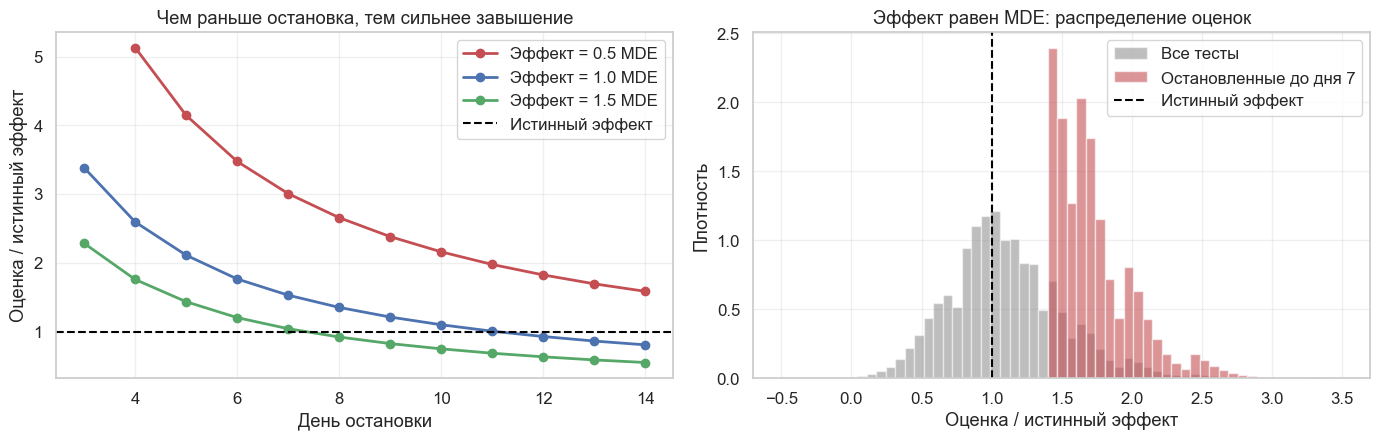

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for effect, color in [(0.5, RED), (1.0, BLUE), (1.5, GREEN)]:
    stop_look, fired, ratio, _ = stopped_estimates(effect)
    by_day = pd.DataFrame({"day": stop_look[fired], "ratio": ratio[fired]}).groupby("day")["ratio"].agg(["mean", "size"])
    by_day = by_day[by_day["size"] >= 300]
    axes[0].plot(by_day.index, by_day["mean"], "-o", color=color, linewidth=2, label=f"Эффект = {effect} MDE")
axes[0].axhline(1, color="black", linestyle="--", linewidth=1.5, label="Истинный эффект")
axes[0].set(xlabel="День остановки", ylabel="Оценка / истинный эффект", title="Чем раньше остановка, тем сильнее завышение")
axes[0].legend()

stop_look, fired, ratio, _ = stopped_estimates(1.0)
bins = np.linspace(-0.5, 3.5, 60)
axes[1].hist(ratio, bins=bins, density=True, color=GRAY, alpha=0.5, label="Все тесты")
axes[1].hist(ratio[fired & (stop_look <= 7)], bins=bins, density=True, color=RED, alpha=0.6, label="Остановленные до дня 7")
axes[1].axvline(1, color="black", linestyle="--", linewidth=1.5, label="Истинный эффект")
axes[1].set(xlabel="Оценка / истинный эффект", ylabel="Плотность", title="Эффект равен MDE: распределение оценок")
axes[1].legend()
plt.tight_layout()
plt.show()

Цифры стоит запомнить:

* Если эффект равен MDE и тест остановился до 7-го дня, оценка в среднем завышена в **1.73 раза**. Такие остановки случаются в 18.5% тестов.
* Если эффект вдвое меньше MDE, значимые тесты завышают его в **2.06 раза**, а ранние остановки в 3.3 раза.
* По всем тестам вместе завышение скромное: 8–10%. В клинических исследованиях та же картина: общее смещение невелико, а для конкретного рано остановленного теста оно большое. И именно такой тест лежит у нас на столе.

Справа красная гистограмма не содержит значений меньше 1.4: тест просто не мог остановиться рано с меньшей оценкой, такой отбор задаёт сама граница. Чем жёстче ранняя граница, тем сильнее завышение у прошедших её.

### Задание 10. Как отчитаться честно

Обычный интервал вокруг такой оценки тоже смещён. Сравним три интервала в момент остановки: обычный, **повторный доверительный интервал** GST ($\hat\Delta \pm b_i \sqrt{V}$) и последовательность mSPRT. Реализуйте `coverage_at_stop(effect, max_day)`: доля остановленных тестов, где интервал накрыл истинный эффект, при остановке не позже дня `max_day`. Заявленный уровень 97.5%.

In [41]:
def coverage_at_stop(effect: float = 1.0, max_day: int = PLAN_DAYS) -> pd.Series:
    # ВАШ КОД
    raise NotImplementedError

In [42]:
# @title Решение (нажмите, чтобы раскрыть)
def coverage_at_stop(effect: float = 1.0, max_day: int = PLAN_DAYS) -> pd.Series:
    stop_look, fired, ratio, _ = stopped_estimates(effect)
    chosen = fired & (stop_look <= max_day)
    drift = effect * drift_mde
    t = LOOKS[stop_look - 1]
    error = np.abs(ratio - 1) * drift
    half_naive = norm.ppf(1 - ALPHA_PRIMARY / 2) / np.sqrt(t)
    half_gst = BOUNDS_OBF[stop_look - 1] / np.sqrt(t)
    half_msprt = msprt_radius(1 / t, TAU / np.sqrt(V_PLAN))
    return pd.Series({"Обычный интервал": (error <= half_naive)[chosen].mean(),
                      "Повторный интервал GST": (error <= half_gst)[chosen].mean(),
                      "Последовательность mSPRT": (error <= half_msprt)[chosen].mean()})

In [43]:
# Проверка
coverage = pd.DataFrame({f"Эффект = {e} MDE": coverage_at_stop(e) for e in (0.5, 1.0, 1.5)})
coverage_early = pd.DataFrame({f"Эффект = {e} MDE, до дня 7": coverage_at_stop(e, max_day=7) for e in (0.5, 1.0, 1.5)})
assert (coverage.loc["Повторный интервал GST"] > coverage.loc["Обычный интервал"]).all()
pd.concat([coverage, coverage_early], axis=1).T

,Обычный интервал,Повторный интервал GST,Последовательность mSPRT
Эффект = 0.5 MDE,0.926,0.999,0.998
Эффект = 1.0 MDE,0.980,1.000,1.000
Эффект = 1.5 MDE,0.982,0.999,1.000
"Эффект = 0.5 MDE, до дня 7",0.267,0.996,0.974
"Эффект = 1.0 MDE, до дня 7",0.911,1.000,0.998
"Эффект = 1.5 MDE, до дня 7",0.975,1.000,1.000


По всем остановкам обычный интервал выглядит терпимо: 93–98%. Но среди остановок до 7-го дня картина другая: 91% при эффекте, равном MDE, и всего 27% при эффекте 0.5 MDE. Повторный интервал и последовательность mSPRT держат уровень при любом дне остановки, и в отчёте нужно показывать их.

Наш отчёт на 6-й день должен звучать так: «эффект есть, повторный интервал от +0.08 до +1.80 п.п.», а не «+0.94 п.п.». Такая формулировка сразу показывает, насколько мало мы знаем о размере эффекта. Есть и специальные поправки точечной оценки (Whitehead, 1986), но у них свой компромисс: Fan, DeMets и Lan (2004) показали, что они могут не убирать смещение для тестов, остановленных на конкретном взгляде.

## 7. Новизна и недельный цикл

Завышение из раздела 6 — это шум. В нашем тесте есть проблема другого рода: сам эффект мог меняться. Здесь работают две причины. Во-первых, частые пользователи попадают в тест раньше редких, поэтому первые дни непредставительны (**heavy-user bias**, Wang et al., 2019). Во-вторых, новый блок цепляет тех, кто знал старый интерфейс: это **эффект новизны**, он со временем ослабевает. Обратный случай, когда пользователю сначала мешает непривычное, называют **эффектом первичности** (Kohavi, Tang, Xu, 2020). В обоих случаях реакция в начале теста не равна реакции в устойчивом режиме.

Открываем все 28 дней.

### Задание 11. Эффект по когортам

Реализуйте `cohort_effects(df, metric, period)`: эффект и 95% ДИ для когорт, пришедших в один и тот же период длиной `period` дней. В отличие от накопленной оценки здесь каждая когорта считается **отдельно**. Заодно раскроем истинные параметры генератора.

Истина: эффект на конверсию равен $0.2 + 0.8 \cdot e^{-(d-1)/4}$ п.п. для когорты дня $d$. Брони в группе B на 5% дешевле из-за скидок, поэтому долгосрочная выручка меняется в $1.04 \cdot 0.95 \approx 0.99$ раза, то есть снижается примерно на 1%. Доля отмен среди броней выросла с 18% до 19.5%.

In [44]:
def cohort_effects(df: pd.DataFrame, metric: str = "booked", period: int = 7) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [45]:
# @title Решение (нажмите, чтобы раскрыть)
def cohort_effects(df: pd.DataFrame, metric: str = "booked", period: int = 7) -> pd.DataFrame:
    cohort = (df["day"] - 1) // period + 1
    grouped = df.groupby([cohort, "group"])[metric].agg(["mean", "var", "size"]).unstack()
    effect = grouped[("mean", "B")] - grouped[("mean", "A")]
    se = np.sqrt(grouped[("var", "A")] / grouped[("size", "A")] + grouped[("var", "B")] / grouped[("size", "B")])
    return pd.DataFrame({"effect": effect, "se": se, "low": effect - 1.96 * se, "high": effect + 1.96 * se})

In [46]:
# Проверка
weekly = cohort_effects(logs)
daily_cohorts = cohort_effects(logs, period=1)
assert len(weekly) == 4 and len(daily_cohorts) == 28
assert daily_cohorts["se"].mean() > weekly["se"].mean()

TRUE_EARLY, TRUE_LATE, TRUE_DECAY = 0.010, 0.002, 4.0


def true_effect(day):
    """Истинный эффект на конверсию для когорты дня day, нумерация с 1."""
    return TRUE_LATE + (TRUE_EARLY - TRUE_LATE) * np.exp(-(np.asarray(day) - 1) / TRUE_DECAY)


cum_full = daily_cumulative(logs, "booked")
msprt_full = replay_msprt(cum_full, TAU)
truth = [true_effect(np.arange(a, a + 7)).mean() for a in (1, 8, 15, 22)]
late = logs[logs["day"] > 7].groupby("group")["booked"]
late_effect = late.mean()["B"] - late.mean()["A"]
late_se = np.sqrt((late.var() / late.size()).sum())
gap = weekly["effect"].iloc[0] - late_effect
gap_z = gap / np.sqrt(weekly["se"].iloc[0] ** 2 + late_se ** 2)
print(f"Дни 8–28: {100 * late_effect:+.2f} п.п. Разность с первой неделей {100 * gap:+.2f} п.п., z = {gap_z:.2f}, p = {2 * norm.sf(abs(gap_z)):.3f}")
pd.DataFrame({"Когорта": ["дни 1–7", "дни 8–14", "дни 15–21", "дни 22–28"], "Оценка, п.п.": 100 * weekly["effect"].values,
              "Нижняя 95%": 100 * weekly["low"].values, "Верхняя 95%": 100 * weekly["high"].values, "Истина, п.п.": 100 * np.array(truth)})

Дни 8–28: +0.17 п.п. Разность с первой неделей +0.75 п.п., z = 2.91, p = 0.004


,Когорта,"Оценка, п.п.",Нижняя 95%,Верхняя 95%,"Истина, п.п."
0,дни 1–7,0.922,0.482,1.362,0.627
1,дни 8–14,0.026,-0.402,0.455,0.274
2,дни 15–21,0.277,-0.154,0.707,0.213
3,дни 22–28,0.209,-0.220,0.638,0.202


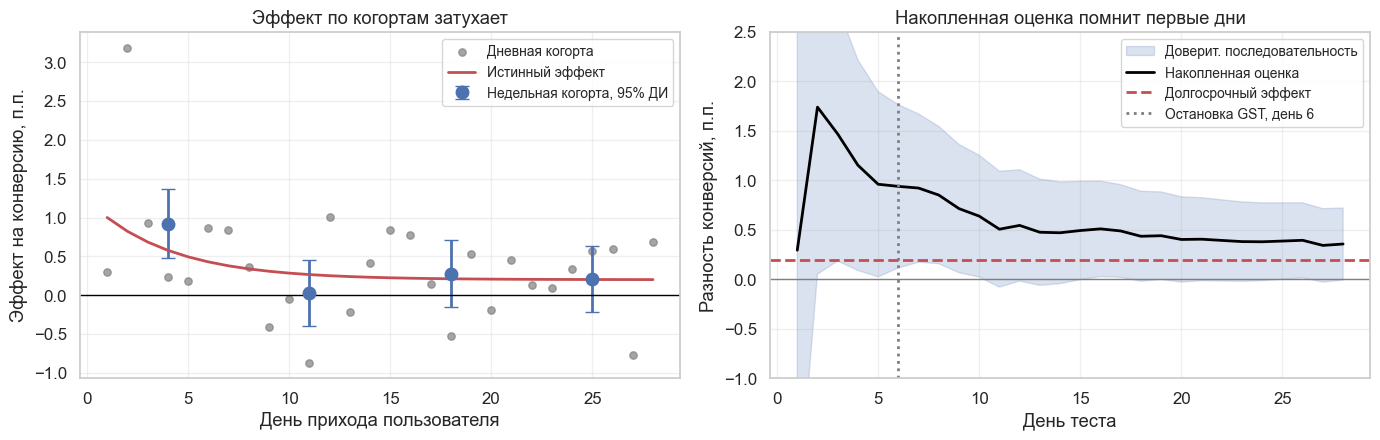

День 6: +0.94 п.п., день 14: +0.47 п.п., день 28: +0.36 п.п., истинный долгосрочный +0.20 п.п.


In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
all_days = np.arange(1, 29)
axes[0].scatter(all_days, 100 * daily_cohorts["effect"], color=GRAY, s=28, alpha=0.7, label="Дневная когорта")
middle = [4, 11, 18, 25]
axes[0].errorbar(middle, 100 * weekly["effect"], yerr=100 * 1.96 * weekly["se"], fmt="o", color=BLUE, markersize=9, capsize=5, linewidth=2, label="Недельная когорта, 95% ДИ")
axes[0].plot(all_days, 100 * true_effect(all_days), color=RED, linewidth=2, label="Истинный эффект")
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set(xlabel="День прихода пользователя", ylabel="Эффект на конверсию, п.п.", title="Эффект по когортам затухает")
axes[0].legend(fontsize=10)

axes[1].fill_between(all_days, 100 * (msprt_full["diff"] - msprt_full["radius"]), 100 * (msprt_full["diff"] + msprt_full["radius"]), color=BLUE, alpha=0.2, label="Доверит. последовательность")
axes[1].plot(all_days, 100 * msprt_full["diff"], color="black", linewidth=2, label="Накопленная оценка")
axes[1].axhline(100 * TRUE_LATE, color=RED, linestyle="--", linewidth=2, label="Долгосрочный эффект")
axes[1].axvline(stop_day, color=GRAY, linestyle=":", linewidth=2, label=f"Остановка GST, день {stop_day}")
axes[1].axhline(0, color=GRAY, linewidth=1)
axes[1].set(xlabel="День теста", ylabel="Разность конверсий, п.п.", ylim=(-1, 2.5), title="Накопленная оценка помнит первые дни")
axes[1].legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f"День {stop_day}: {100 * cum_full.loc[stop_day, 'diff']:+.2f} п.п., день 14: {100 * cum_full.loc[14, 'diff']:+.2f} п.п., день 28: {100 * cum_full.loc[28, 'diff']:+.2f} п.п., истинный долгосрочный {100 * TRUE_LATE:+.2f} п.п.")

Вот что не сказала ни одна значимость. Когорта первой недели дала +0.92 п.п., а три следующие: +0.03, +0.28 и +0.21 п.п. Истинный долгосрочный эффект равен **+0.2 п.п.**, в 4.7 раза меньше оценки на день остановки.

**Осторожно с графиками.** Убывающая накопленная оценка сама по себе новизну **не доказывает**. Kohavi et al. (2012) показывают: тренд накопленного эффекта в первые дни часто оказывается просто шумом ранних оценок, а у рано остановленного теста к нему добавляется отбор из раздела 6. Поэтому сравниваем непересекающиеся когорты с интервалами: поздние когорты не зависят от момента остановки. Разность первой недели и трёх поздних значима, это напечатано под таблицей.

Правый график показывает две вещи:

* Накопленная оценка помнит первые дни: даже на 28-й день она равна +0.36 п.п., потому что в ней сидит первая неделя.
* mSPRT сработал на 2-й день, но на 11-й день ноль снова внутри последовательности и до конца теста держится у её нижней границы. Гарантия always-valid вывода сформулирована для **постоянного** параметра. Если эффект меняется, последовательность накрывает среднее по уже пришедшим пользователям, а не будущий эффект.

**Важно разделять.** Завышение из раздела 6 исчезает, если эффект измерить на большей выборке того же типа. Новизна не исчезает, пока накопленная оценка содержит ранние когорты. Никакая поправка $\alpha$ тут не поможет, потому что статистика отвечает на вопрос о пришедших пользователях, а бизнес спрашивает о будущих.

### Задание 12. Правило минимальной длительности

Сравним правила на 20 000 повторениях нашего сценария с известной истиной. Реализуйте `simulate_rules(R, seed)`: генерируйте дневные конверсии по истинным параметрам (будни 2 800 и 5%, выходные 3 500 и 5.6% на группу, понедельник в начале) и для каждого правила считайте долю значимых тестов, средний и медианный день решения и среднюю оценку среди значимых:

1. первое срабатывание GST при ежедневных взглядах;
2. не раньше дня 7, затем каждый день;
3. два взгляда: дни 7 и 14;
4. один взгляд на день 14 при уровне 2.5%;
5. один взгляд на день 28;
6. оценка только по когортам дней 8–14 на день 14.

В правилах 2 и 3 границы пересчитываются на фактический набор взглядов: пропущенный взгляд не тратит $\alpha$.

In [48]:
def simulate_rules(R: int = 20_000, seed: int = 8) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [49]:
# @title Решение (нажмите, чтобы раскрыть)
def simulate_rules(R: int = 20_000, seed: int = 8) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2026-09-07", periods=28)
    weekend = dates.dayofweek >= 5
    n = np.where(weekend, 3_500, 2_800)
    base = np.where(weekend, 0.056, 0.050)
    x_a = rng.binomial(n, base, (R, 28))
    x_b = rng.binomial(n, base + true_effect(np.arange(1, 29)), (R, 28))
    n_cum, a_cum, b_cum = n.cumsum(), x_a.cumsum(axis=1), x_b.cumsum(axis=1)
    p_a, p_b = a_cum / n_cum, b_cum / n_cum
    diff = p_b - p_a
    z = diff / np.sqrt((p_a * (1 - p_a) + p_b * (1 - p_b)) / n_cum)
    share = np.minimum(n_cum[:14] / n_cum[13], 1.0)

    def run(days) -> dict:
        """Применяет GST со взглядами только в перечисленные дни."""
        days = np.asarray(days)
        bounds = gst_boundaries(obf_spending, share[days - 1], n_paths=500_000) if len(days) > 1 else np.array([norm.ppf(1 - ALPHA_PRIMARY / 2)])
        hits = np.abs(z[:, days - 1]) >= bounds
        fired = hits.any(axis=1)
        first = hits.argmax(axis=1)[fired]
        return {"Значимо": fired.mean(), "Средний день": days[first].mean(), "Медианный день": np.median(days[first]),
                "Оценка, п.п.": 100 * diff[fired, days[first] - 1].mean()}

    rows = {"Первое срабатывание, взгляды каждый день": run(np.arange(1, 15)),
            "Не раньше дня 7, потом каждый день": run(np.arange(7, 15)),
            "Два взгляда: дни 7 и 14": run(np.array([7, 14])),
            "Один взгляд на день 14": run(np.array([14])),
            "Один взгляд на день 28": run(np.array([28]))}

    a_late, b_late = x_a[:, 7:14].sum(axis=1), x_b[:, 7:14].sum(axis=1)
    n_late = n[7:14].sum()
    diff_late = (b_late - a_late) / n_late
    p_late = (a_late + b_late) / (2 * n_late)
    z_late = diff_late / np.sqrt(2 * p_late * (1 - p_late) / n_late)
    rows["Когорты 8–14 дня, день 14"] = {"Значимо": (np.abs(z_late) >= norm.ppf(1 - ALPHA_PRIMARY / 2)).mean(), "Средний день": 14.0,
                                          "Медианный день": 14.0, "Оценка, п.п.": 100 * diff_late.mean()}
    table = pd.DataFrame(rows).T
    table["Завышение к долгосрочному"] = table["Оценка, п.п."] / (100 * TRUE_LATE)
    return table

In [50]:
# Проверка
rules = simulate_rules()
assert rules["Завышение к долгосрочному"].iloc[0] > rules["Завышение к долгосрочному"].iloc[-2]
assert rules.loc["Один взгляд на день 28", "Средний день"] == 28
rules

,Значимо,Средний день,Медианный день,"Оценка, п.п.",Завышение к долгосрочному
"Первое срабатывание, взгляды каждый день",0.747,8.328,8.000,0.754,3.769
"Не раньше дня 7, потом каждый день",0.749,8.851,8.000,0.690,3.451
Два взгляда: дни 7 и 14,0.734,10.720,14.000,0.648,3.242
Один взгляд на день 14,0.724,14.000,14.000,0.516,2.580
Один взгляд на день 28,0.762,28.000,28.000,0.370,1.849
"Когорты 8–14 дня, день 14",0.163,14.000,14.000,0.273,1.366


Что показывает таблица:

* **Первое срабатывание** находит «эффект» в 75% тестов, в среднем и в медиане на 8-й день. Оценка +0.75 п.п. завышает долгосрочный эффект в 3.8 раза. Наш лог с остановкой на 6-й день — обычный исход, просто немного быстрее медианного.
* **Минимальная длительность снижает завышение, но не убирает:** запрет смотреть раньше дня 7 даёт 3.5 раза, один взгляд на день 14 даёт 2.6 раза, на день 28 всё ещё 1.8 раза.
* **Когорты дней 8–14** почти честны, завышение 1.4 раза, зато их мало, значимость получается лишь в 16% случаев.

Отсюда практическое правило, а не просто «ждать дольше»:

1. Минимум один полный недельный цикл до любого решения о раскатке. Лучше две недели: поведение в будни и выходные различается (1.П2), а первая неделя непредставительна.
2. Раннюю остановку разрешаем только **за вред**. Остановка за успех на первой неделе приносит оценку, которой нельзя верить.
3. Обязательно смотрим эффект по когортам. Если поздние когорты заметно слабее ранних, решение принимаем по поздним, а тест при возможности продлеваем.
4. После раскатки оставляем контрольную группу (holdout), чтобы померить устойчивый эффект.

## 8. Срыв плана

В реальности план редко выполняется точно: падает пайплайн, продакт просит «ещё неделю», а кто-то смотрит результаты внепланово. Проверим, что из этого опасно.

### Задание 13. Выход за $N_{\max}$

Самая частая ситуация: к дню 14 границу не прошли, и тест решают продлить. Реализуйте `overrun_fpr(extra_days, repeat_last_bound, ...)`: при верной $H_0$ тест идёт по плану 14 дней, затем ещё `extra_days` дней. Если `repeat_last_bound=True`, каждый дополнительный день проверяем с последней границей. Если `False`, проверяем один раз в конце продления.

In [51]:
def overrun_fpr(extra_days: int, repeat_last_bound: bool, n_paths: int = 1_000_000, seed: int = 21) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [52]:
# @title Решение (нажмите, чтобы раскрыть)
def overrun_fpr(extra_days: int, repeat_last_bound: bool, n_paths: int = 1_000_000, seed: int = 21) -> float:
    days = np.arange(1, PLAN_DAYS + extra_days + 1) / PLAN_DAYS
    z = np.abs(null_paths(days, n_paths, seed))
    fired = (z[:, :PLAN_DAYS] >= BOUNDS_OBF).any(axis=1)
    if repeat_last_bound:
        fired |= (z[:, PLAN_DAYS:] >= BOUNDS_OBF[-1]).any(axis=1)
    else:
        fired |= z[:, -1] >= BOUNDS_OBF[-1]
    return float(fired.mean())

In [53]:
# Проверка
assert abs(overrun_fpr(0, True) - ALPHA_PRIMARY) < 0.002
assert overrun_fpr(7, True) > overrun_fpr(7, False) > ALPHA_PRIMARY


def deviation_table(n_paths: int = 1_000_000, seed: int = 21) -> pd.DataFrame:
    """Сравнивает долю ложных срабатываний при отклонениях от плана."""
    all_days = np.arange(1, 22)
    t = all_days / PLAN_DAYS
    z = np.abs(null_paths(t, n_paths, seed))

    lost = np.array([d for d in range(1, 15) if d not in (3, 4, 9)])
    bounds_lost = gst_boundaries(obf_spending, lost / PLAN_DAYS)

    weekly_days = np.array([7, 14])
    extra_days = np.array([7, 10, 14])
    bounds_weekly = gst_boundaries(obf_spending, weekly_days / PLAN_DAYS)
    bounds_extra = gst_boundaries(obf_spending, extra_days / PLAN_DAYS)
    promising = z[:, 6] >= 1.5
    weekly_hit = (z[:, weekly_days - 1] >= bounds_weekly).any(axis=1)
    extra_hit = (z[:, extra_days - 1] >= bounds_extra).any(axis=1)

    z_fixed = norm.ppf(1 - ALPHA_PRIMARY / 2)
    plan_fired = (z[:, :14] >= BOUNDS_OBF).any(axis=1)
    near_miss = ~plan_fired & (z[:, 13] >= norm.ppf(1 - 0.20 / 2))
    tau_unit = TAU / np.sqrt(V_PLAN)
    signed = null_paths(t, n_paths, seed)
    msprt_hits = msprt_log_lambda(signed * np.sqrt(1 / t), 1 / t, tau_unit) >= np.log(1 / ALPHA_PRIMARY)

    table = {
        "План: 14 взглядов": plan_fired.mean(),
        "Потеряны дни 3, 4, 9, границы пересчитаны": (z[:, lost - 1] >= bounds_lost).any(axis=1).mean(),
        "Внеплановый взгляд по тренду, границы пересчитаны": np.where(promising, extra_hit, weekly_hit).mean(),
        "Выход на день 21, последняя граница каждый день": overrun_fpr(7, True),
        "Выход на день 21, один взгляд": overrun_fpr(7, False),
        "Близко к порогу: ещё неделя и обычный порог": (plan_fired | (near_miss & (z[:, 20] >= z_fixed))).mean(),
        "mSPRT: каждый день до дня 14": msprt_hits[:, :14].any(axis=1).mean(),
        "mSPRT: каждый день до дня 21": msprt_hits.any(axis=1).mean(),
    }
    return pd.Series(table, name="Ложных срабатываний").to_frame()


deviations = deviation_table()
deviations

,Ложных срабатываний
План: 14 взглядов,0.025
"Потеряны дни 3, 4, 9, границы пересчитаны",0.025
"Внеплановый взгляд по тренду, границы пересчитаны",0.025
"Выход на день 21, последняя граница каждый день",0.044
"Выход на день 21, один взгляд",0.034
Близко к порогу: ещё неделя и обычный порог,0.038
mSPRT: каждый день до дня 14,0.005
mSPRT: каждый день до дня 21,0.006


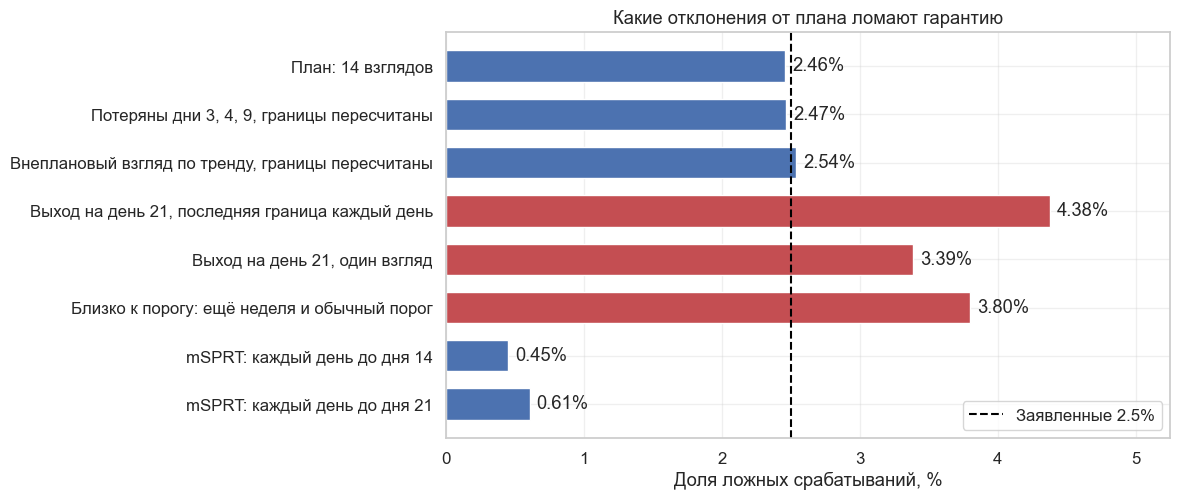

In [54]:
order = deviations["Ложных срабатываний"].iloc[::-1]
colors = [RED if v > ALPHA_PRIMARY * 1.08 else BLUE for v in order.values]
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.barh(order.index, 100 * order.values, color=colors, height=0.65)
ax.axvline(100 * ALPHA_PRIMARY, color="black", linestyle="--", linewidth=1.5, label="Заявленные 2.5%")
for i, v in enumerate(order.values):
    ax.text(100 * v + 0.05, i, f"{100 * v:.2f}%", va="center")
ax.set(xlabel="Доля ложных срабатываний, %", xlim=(0, 1.2 * 100 * order.max()), title="Какие отклонения от плана ломают гарантию")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Отклонения делятся на две группы.

**Безвредные** (ошибка около 2.5%). Пропуск дней при пересчёте границ по фактическим долям ничего не ломает. Внеплановый взгляд, назначенный по тренду, при той же функции расхода почти безвреден: 2.54% в нашем сценарии. Функция $\alpha(t)$ защищает сама, потому что каждый взгляд тратит только свой прирост. Формально это всё же нарушение: у пересчёта нет гарантии, если моменты взглядов зависят от данных, поэтому такие взгляды лучше не делать привычкой.

**Опасные** (ошибка 3.4–4.4%). Всё, что выходит за $N_{\max}$: вся $\alpha$ к этому моменту потрачена, новых взглядов бюджет не предусматривает. Именно на это указывает и Spotify: GST завышает ошибку при выходе за план. «Ещё неделю и обычный порог для почти значимого» даёт 3.8%, полуторакратное завышение.

**mSPRT** к продлению равнодушен: ошибка остаётся ниже заявленной при любом горизонте. Это и есть его настоящее преимущество, за которое мы заплатили мощностью в разделе 3.

**Вопрос.** Как поступить, если продлить тест всё-таки нужно?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Закладывать это до запуска: взять $N_{\max}$ с запасом и функцию расхода, которая мало тратит в начале. Тогда раннее окончание остаётся возможным, а поздние данные не выходят за план. Если неопределённость по длительности велика с самого начала, это аргумент за always-valid подход. Если продление всё же случилось без плана, то честный статус результата — разведочный: новый тест с заранее заданным планом стоит дешевле, чем ложный запуск.

</details>

## 9. Решение и регламент

Соберём всё, что у нас есть, на три момента времени: день остановки, плановый день 14 и день 28. Интервалы здесь — доверительные последовательности mSPRT, потому что они корректны на любой день. Последняя строка для отмен использует обычный односторонний тест: на плановом взгляде он законен и мощнее последовательности.

### Задание 14. Решение

Напишите короткое сообщение продакту (3–5 предложений): что произошло с метриками, раскатываем ли блок и что делаем дальше.

*Ваш ответ:*

In [55]:
def status(result: pd.DataFrame, day: int, scale: float) -> str:
    """Форматирует оценку и доверительную последовательность на день day."""
    row = result.loc[day]
    return f"{row['diff'] * scale:+.2f} [{(row['diff'] - row['radius']) * scale:+.2f}; {(row['diff'] + row['radius']) * scale:+.2f}]"


def one_sided_p(result: pd.DataFrame, day: int) -> str:
    """Считает обычный односторонний p-value роста на день day."""
    row = result.loc[day]
    return f"{norm.sf(row['diff'] / np.sqrt(row['V'])):.3f}"


full_rev = replay_msprt(daily_cumulative(logs, "revenue_capped"), TAU_REV)
full_cancel = replay_msprt(daily_cumulative(logs, "cancelled"), TAU_CANCEL, alpha=2 * ALPHA)
report = pd.DataFrame({f"День {d}": {"Конверсия, п.п.": status(msprt_full, d, 100),
                                      "Выручка с порогом, ₽": status(full_rev, d, 1),
                                      "Отмены, п.п. (α = 10%)": status(full_cancel, d, 100),
                                      "Отмены: односторонний p обычного теста": one_sided_p(full_cancel, d)}
                       for d in (stop_day, 14, 28)})
harm_day = int(full_cancel.index[((full_cancel["diff"] - full_cancel["radius"]) > 0).argmax()]) if ((full_cancel["diff"] - full_cancel["radius"]) > 0).any() else None
print(f"Вред по отменам виден с дня: {harm_day}")
report

Вред по отменам виден с дня: 20


,День 6,День 14,День 28
"Конверсия, п.п.",+0.94 [+0.11; +1.76],+0.47 [-0.04; +0.98],+0.36 [-0.01; +0.72]
"Выручка с порогом, ₽",+179.21 [-193.12; +551.54],+91.79 [-123.23; +306.81],+49.28 [-99.01; +197.57]
"Отмены, п.п. (α = 10%)",+0.11 [-0.22; +0.43],+0.15 [-0.04; +0.34],+0.22 [+0.08; +0.36]
Отмены: односторонний p обычного теста,0.166,0.016,0.000


<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* **Конверсия.** Рост есть, но он живёт в первой неделе: +0.94 п.п. на день 6, +0.47 п.п. на день 14, а в поздних когортах около +0.2 п.п., что вдвое ниже MDE.
* **Выручка.** Значимого роста нет ни на один из моментов. Брони дешевле, поэтому увеличение числа бронирований почти полностью съедается скидкой.
* **Отмены.** На день 6 сигнала нет (p = 0.17), а на плановый день 14 рост значим (p = 0.016), и к дню 28 он виден уже и в последовательности: она исключает ноль с дня 20.

Ранняя остановка пропустила вред: на 6-й день у контрольной метрики просто не хватало данных.

**Решение: блок в текущем виде не раскатываем.** По правилу, принятому до старта, значимый рост конверсии не открывает раскатку, потому что контрольная метрика значимо ухудшилась. Вдобавок устойчивый эффект оказался ниже MDE, а выручка не выросла. Предлагаем доработать блок: понять, почему растут отмены, и пересмотреть глубину скидок. Новый тест запускаем с минимальной длительностью две недели и анализом по когортам.

</details>

### Регламент для команды

| Ситуация | Что делаем |
|---|---|
| Размер выборки хорошо известен, данные приходят раз в день, выходить за план не нужно | **GST** с функцией O'Brien–Fleming и запасом выборки |
| Размер выборки неизвестен или тест может продлиться | **mSPRT** с $\tau$ по плановому объёму, принимая потерю мощности |
| Нужно быстро ловить поломку или сильный вред | **mSPRT** на контрольных метриках, с раннего дня и в потоке. Так Netflix следит за регрессиями при выкатке релизов |
| Взглядов мало, они известны заранее | **GST** или Бонферрони |
| Малый трафик и неравный сплит | Сначала A/A-симуляция на своей метрике, нормальному приближению не верим |

**Что обязательно при любом методе:**

1. План фиксируем до запуска: метрики, роли, $\alpha$, MDE, $N_{\max}$, функция расхода или $\tau$, порог капирования.
2. Раньше полного недельного цикла за успех не останавливаемся, за вред можно.
3. Отчитываемся повторным интервалом или доверительной последовательностью, а не точечной оценкой на момент остановки.
4. Перед решением смотрим эффект по когортам.
5. Контрольной метрике тоже нужна мощность. Если тест остановился рано, её могло не хватить, и отсутствие сигнала ничего не значит.
6. За план не выходим. Вышли — результат считается разведочным.

## Итоги

* Ежедневные взгляды в обычный тест дают 21.8% ложных срабатываний вместо 5%.
* Запас выборки GST зависит от функции расхода: около 5% у O'Brien–Fleming против около 25% у Pocock при 14 взглядах.
* $\tau$ выбирается из плана, и при обычных $\alpha$ и мощности это почти точно MDE. mSPRT платит мощностью за свободу не фиксировать горизонт: 55% против 82%.
* Один выброс не вызывает ложной остановки, он раздувает собственную дисперсию. Опасны неравный сплит и малая выборка.
* Ранняя остановка завышает оценку: в 1.7 раза при эффекте, равном MDE, и остановке на первой неделе.
* Новизну не исправляет никакая поправка на подглядывание: её находит анализ когорт.
* За $N_{\max}$ GST выходить нельзя, mSPRT можно.
* Статистически честная остановка не гарантирует верного продуктового решения.

### Дополнительные задания

1. **Остановка за бесперспективностью.** Добавьте к GST нижнюю границу: останавливаем тест, если условная мощность при MDE упала ниже 20%. Как это изменит среднюю выборку при $H_0$ и мощность при MDE?
2. **CUPED внутри GST.** Снижение дисперсии (лекция 1.04) уменьшает $V$ на каждом взгляде. Сколько дней сэкономит снижение дисперсии на 30%, если $\rho^2$ между метрикой и её предпериодом равен 0.3? Почему доля данных при этом считается по информации, а не по числу пользователей?
3. **Асимптотические последовательности.** Сравните радиус mSPRT с формулой Waudby-Smith et al. (см. документацию GrowthBook). Покажите, что они совпадают при $\rho^2 = \tau^2 / v$, где $v$ — дисперсия одной пары наблюдений. Что это значит для выручки, у которой распределение не нормальное?
4. **Эффект первичности.** Поменяйте в генераторе знак затухающей части: ранние когорты реагируют хуже поздних. Как поведёт себя правило первого срабатывания?

### Источники

1. [Johari, Pekelis, Walsh — Always Valid Inference: Bringing Sequential Analysis to A/B Testing](https://arxiv.org/abs/1512.04922)
2. [Waudby-Smith et al. — Time-uniform central limit theory and asymptotic confidence sequences (Annals of Statistics, 2024)](https://doi.org/10.1214/24-AOS2408)
3. [Schultzberg, Ankargren — Choosing a sequential testing framework (Spotify)](https://engineering.atspotify.com/2023/03/choosing-sequential-testing-framework-comparisons-and-discussions)
4. [Sequential Testing (документация GrowthBook)](https://docs.growthbook.io/statistics/sequential)
5. [Kohavi, Deng, Longbotham, Xu — Seven Rules of Thumb for Web Site Experimenters (KDD 2014)](https://exp-platform.com/rules-of-thumb/)
6. [Kohavi et al. — Trustworthy Online Controlled Experiments: Five Puzzling Outcomes Explained (KDD 2012)](https://exp-platform.com/puzzling-outcomes/)
7. Kohavi, Tang, Xu — *Trustworthy Online Controlled Experiments: A Practical Guide to A/B Testing* (Cambridge University Press, 2020).
8. [Whitehead — On the bias of maximum likelihood estimation following a sequential test (Biometrika, 1986)](https://doi.org/10.1093/biomet/73.3.573)
9. [Fan, DeMets, Lan — Conditional bias of point estimates following a group sequential test (Journal of Biopharmaceutical Statistics, 2004)](https://doi.org/10.1081/bip-120037195)
10. [Walter et al. — Randomised trials with provision for early stopping for benefit (or harm) (Statistics in Medicine, 2019)](https://doi.org/10.1002/sim.8142)
11. [Использование последовательного тестирования для уменьшения размера выборки (Т-Банк)](https://habr.com/ru/articles/876984/)
12. [Проблема подглядывания и последовательное А/Б тестирование (X5 Tech)](https://habr.com/ru/companies/X5Tech/articles/926546/)
13. [Lindon et al. — Rapid Regression Detection in Software Deployments through Sequential Testing (Netflix, KDD 2022)](https://arxiv.org/abs/2205.14762)
14. [Wang et al. — On Heavy-user Bias in A/B Testing (CIKM 2019)](https://arxiv.org/abs/1902.02021)